# Static distortions: every comparison, the TPC tilt and z shift
The story so far: with the current map we can remove the space charge at low luminosity (beam − no beam), and maybe at
high luminosity with better module gains. But the absolute keff came out too large. We **under-estimate the static
distortion and compensate it with extra space charge**. This notebook collects everything that pins down the static
part:

- dφ and dR vs φ and vs R, for every comparison:
  - field off vs truth;
  - no beam (field on) vs truth;
  - no beam − field off;
  - beam vs truth;
  - beam − field off;
  - beam − no beam.

  Each is shown uncorrected and corrected, then stage by stage.
- The TPC rotation scan (z −40): does a tilt remove the first harmonic (sine) in φ, or is more needed?
- The TPC z-shift scan.

Every figure has two panels (South | North). dφ = RΔφ / R in mrad; dR in mm. Medians in 10° φ bins or 3.75 cm rings.
**Note:** the no-beam truth matching picks wrong stripes, so "no beam vs truth" is shown dotted and grey, for
completeness only.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import staticqa as sq, bsnb as b, cmplots as c, v2plots as v
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 15, 'axes.titlesize': 16, 'axes.labelsize': 17, 'legend.fontsize': 12,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'figure.titlesize': 17})
b.plt.rcParams.update(plt.rcParams)
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
STATIC = 'static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)'
SC16 = 'alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347) + ' + STATIC

## 1. Overview: all comparisons together
### 1a. Uncorrected

CONFIG  no PHGarfield correction; field off 78242, no beam 75073 / 83319, beam 795xx (11 blocks)


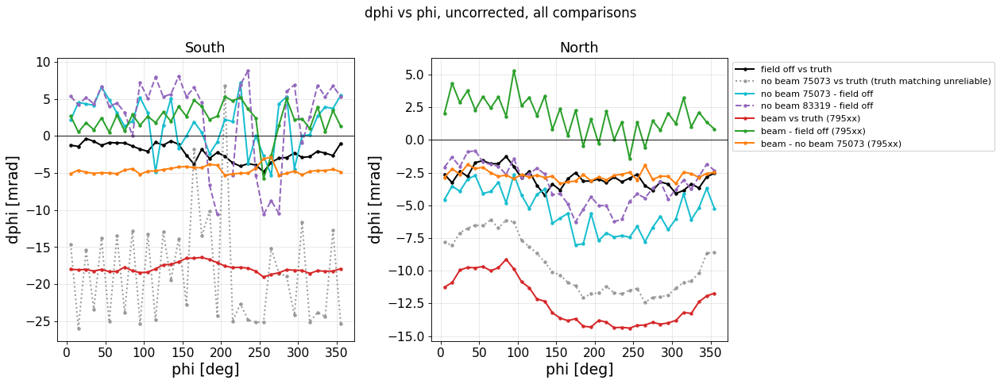

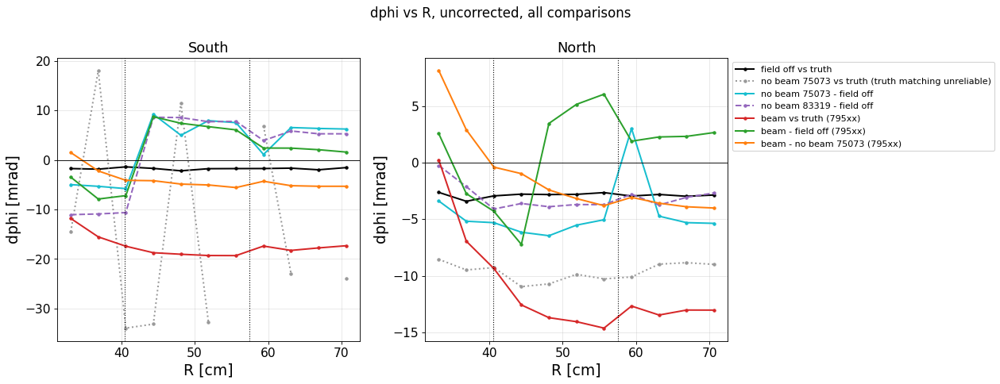

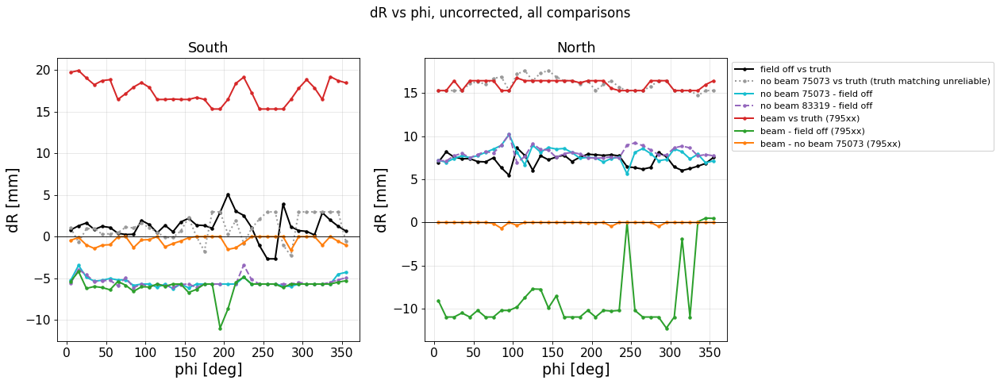

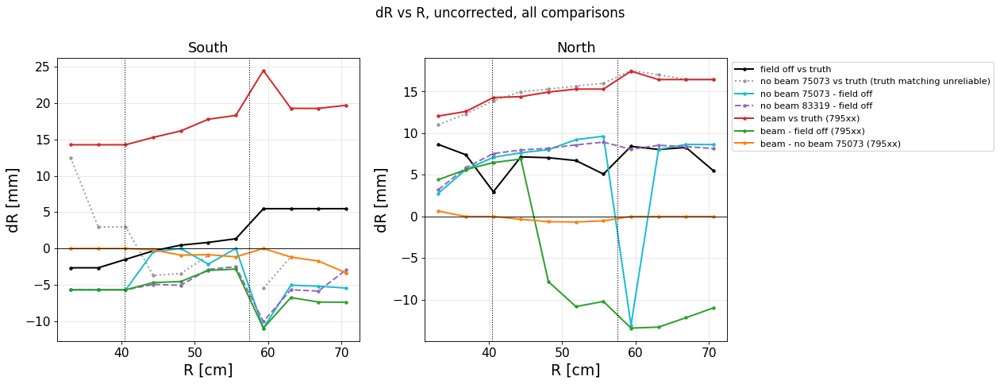

In [2]:
print('CONFIG  no PHGarfield correction; field off 78242, no beam 75073 / 83319, beam 795xx (11 blocks)')
for qn in ('dphi', 'dR'):
    for ax in ('phi', 'R'):
        show(sq.overview('raw', 'raw', qn, ax, 'uncorrected, all comparisons'))

### 1b. Corrected: static model for no beam / field off; full correction (α 1.6, space-charge keff) for beam

CONFIG  no beam / field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) | beam: alpha 1.6 map, keff = 0.596 x I_side (79513/0: S 1.281, N 1.347) + static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


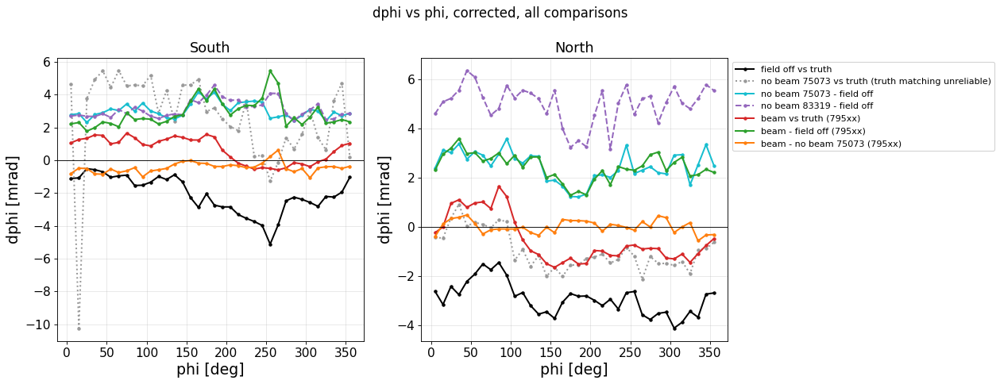

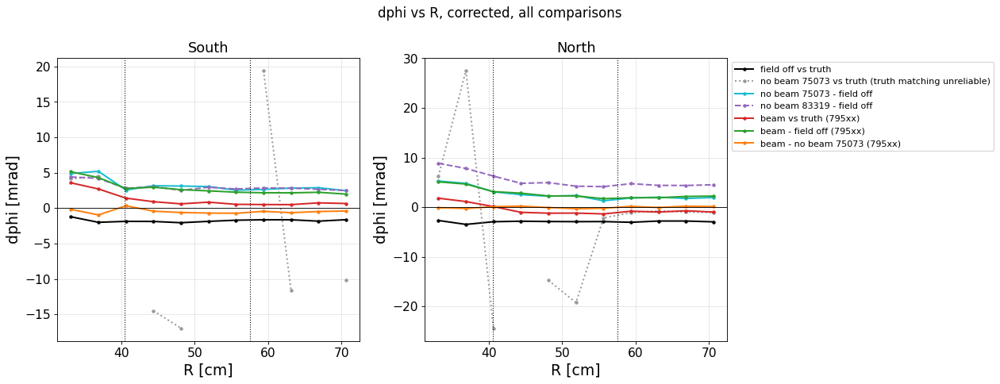

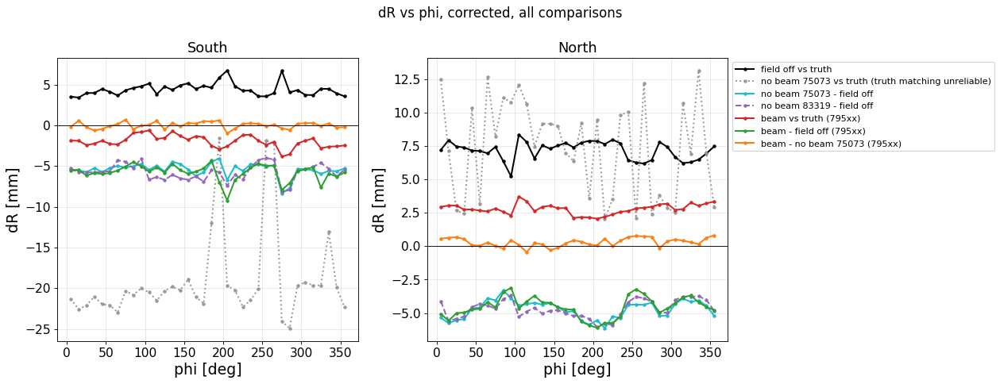

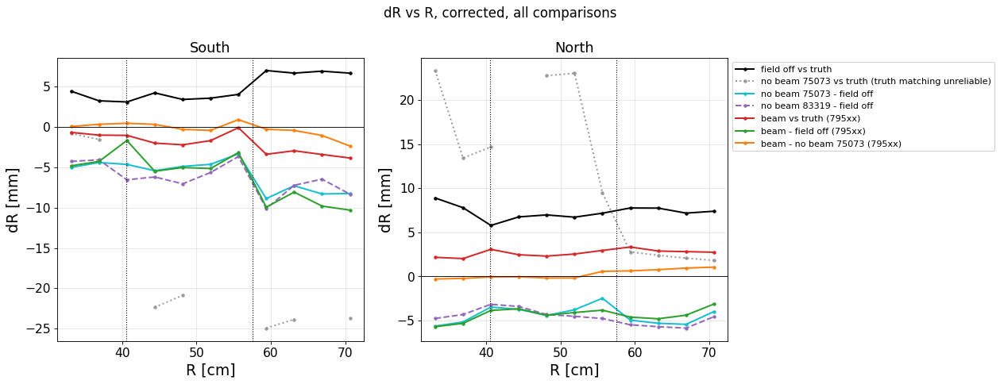

CONFIG  beam at the laser-absolute keff instead: alpha 2.0, keff 0.843 x I_side (79513/0: S 1.811, N 1.904) + static


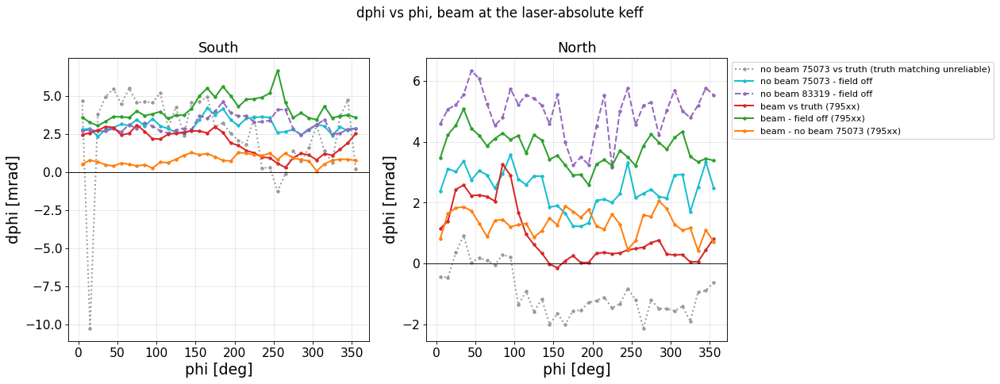

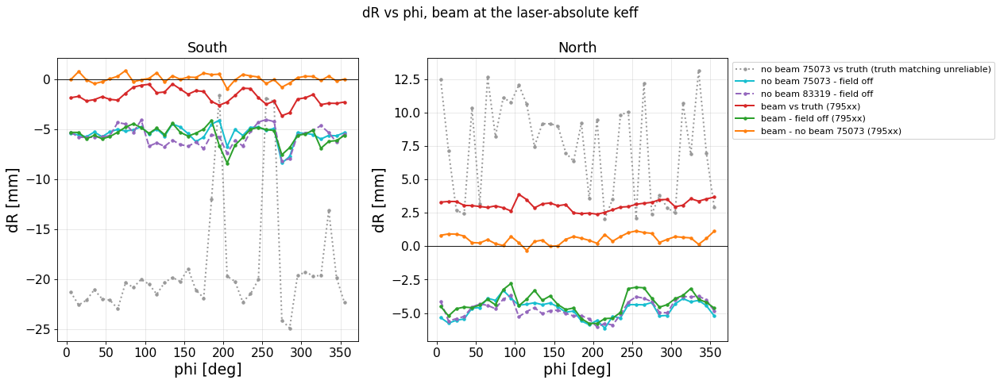

In [3]:
print('CONFIG  no beam / field off: ' + STATIC + ' | beam: ' + SC16)
for qn in ('dphi', 'dR'):
    for ax in ('phi', 'R'):
        show(sq.overview('sc16', 'static', qn, ax, 'corrected, all comparisons'))
print('CONFIG  beam at the laser-absolute keff instead: alpha 2.0, keff 0.843 x I_side (79513/0: S 1.811, N 1.904) + static')
for qn in ('dphi', 'dR'):
    show(sq.overview('final', 'static', qn, 'phi', 'beam at the laser-absolute keff', include=('beam',)))

## 2. Each comparison, stage by stage
No correction → static only → α 1.6 at the space-charge keff → α 2.0 at the laser-absolute keff (beam only).

CONFIG  field off 78242 vs truth: stages raw, static; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


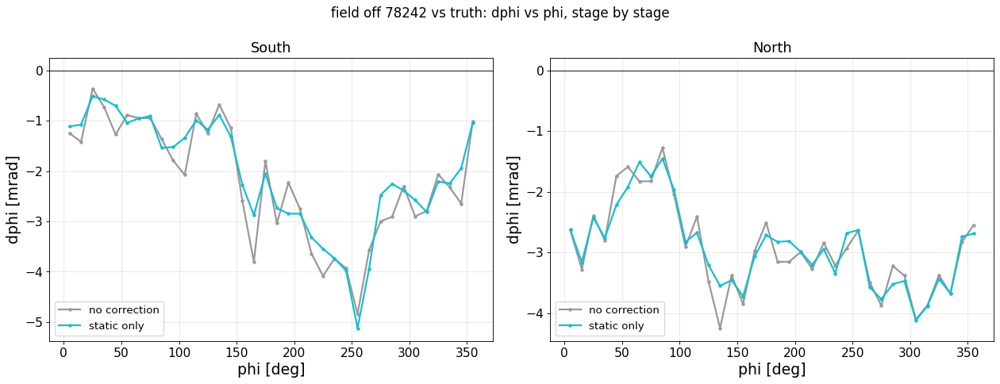

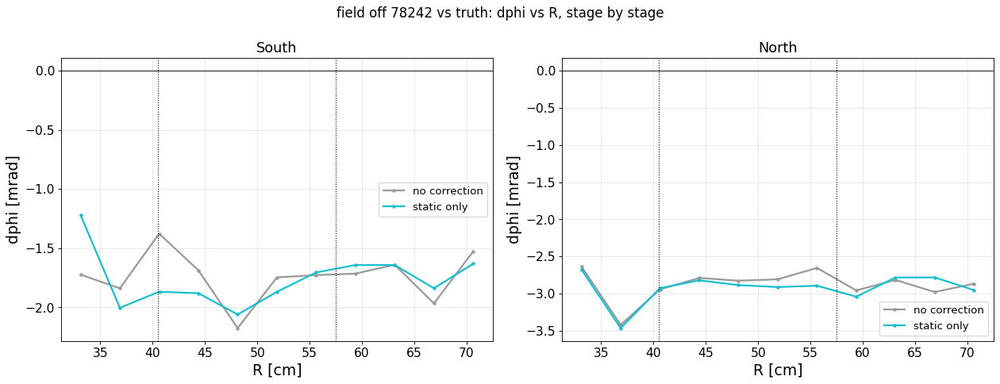

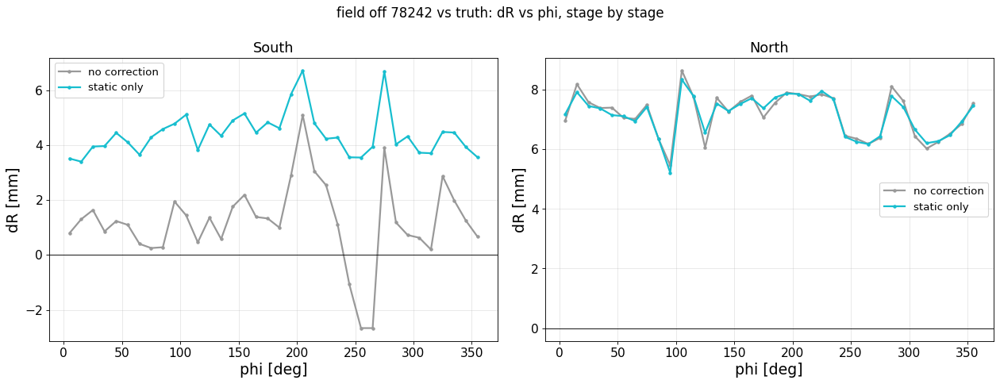

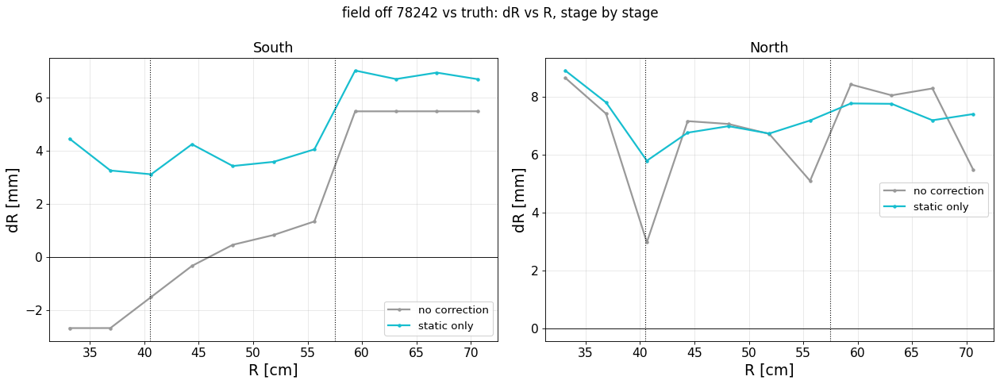

CONFIG  no beam 75073 - field off: stages raw, static; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


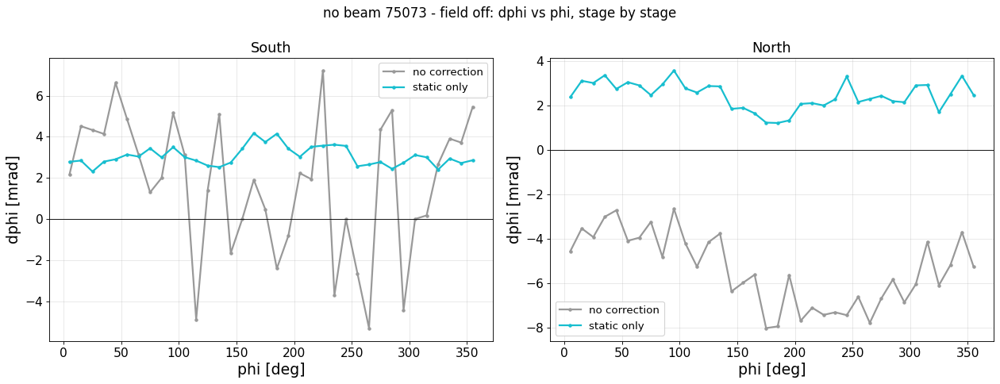

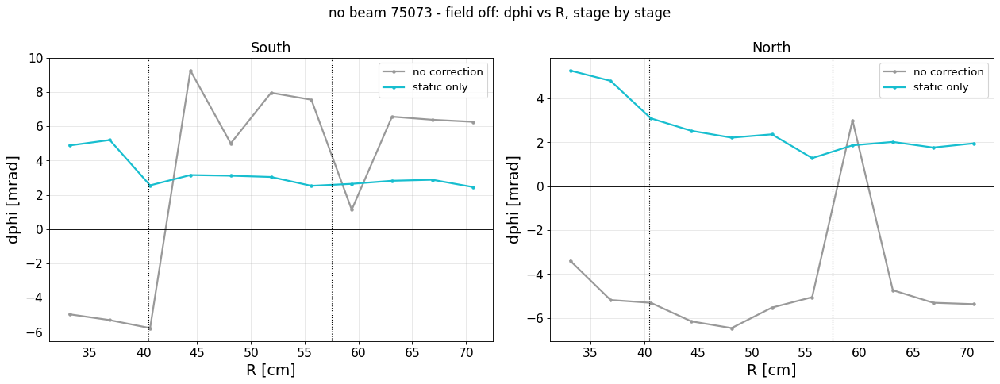

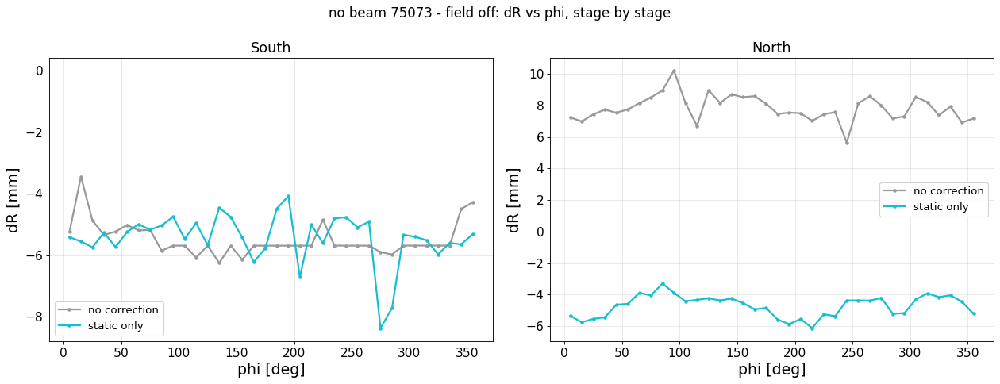

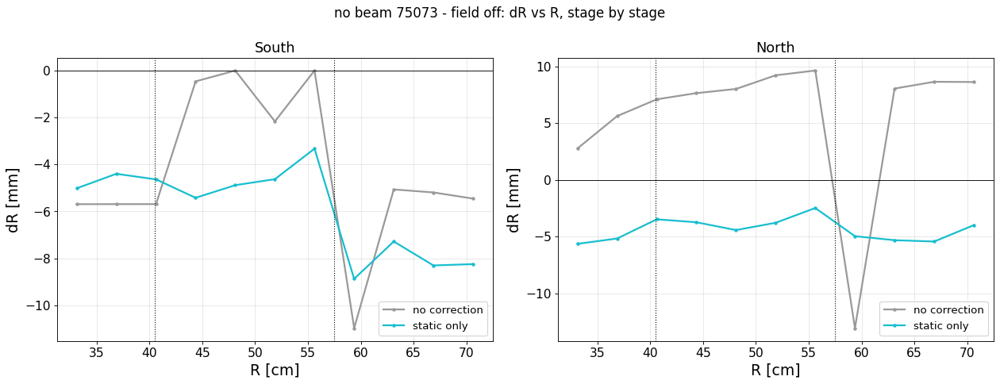

CONFIG  no beam 83319 - field off: stages raw, static; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


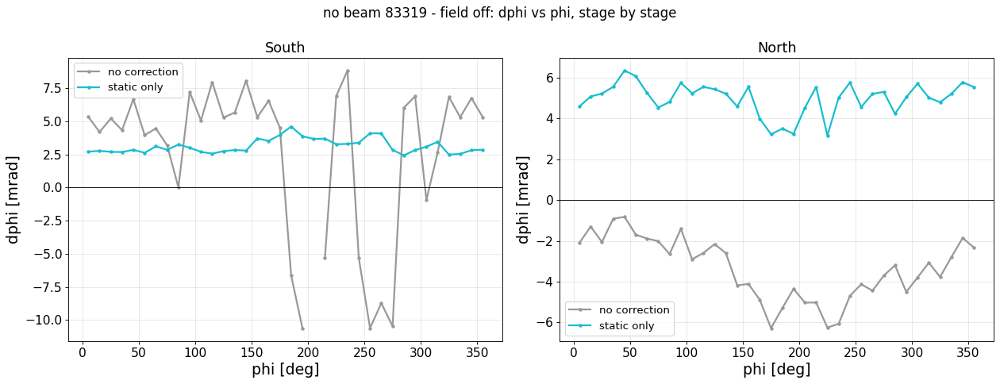

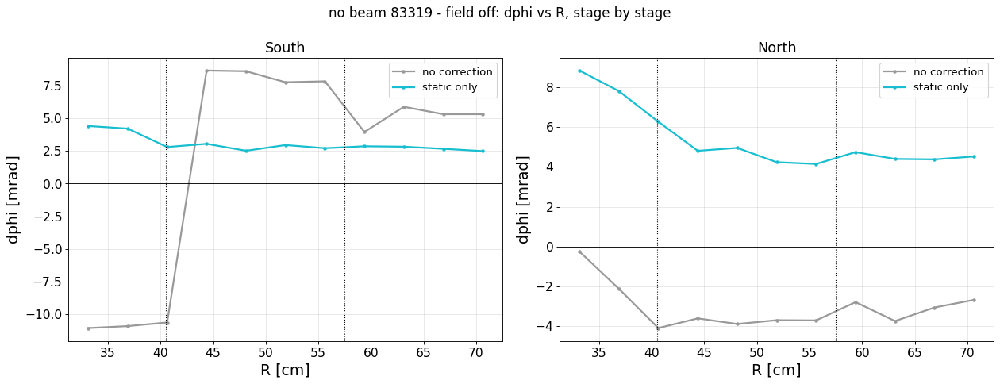

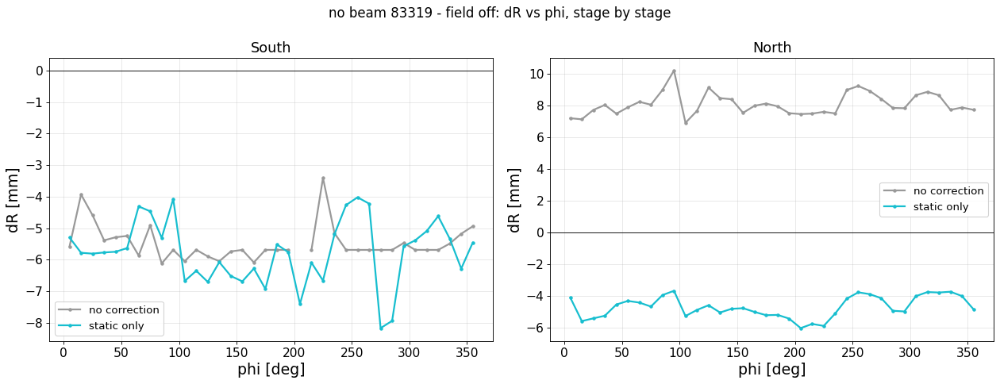

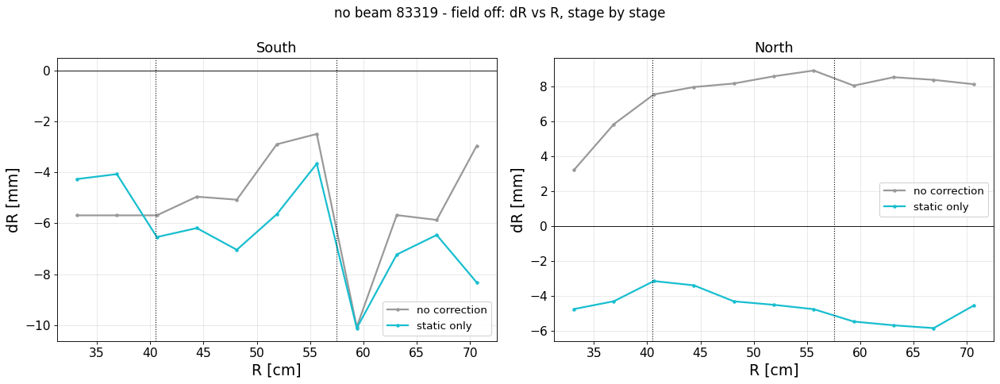

CONFIG  beam vs truth (795xx): stages raw, static, sc16, final; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


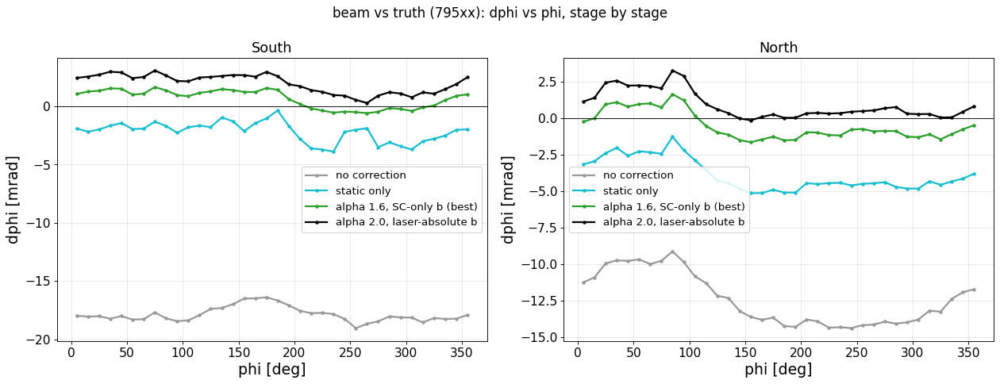

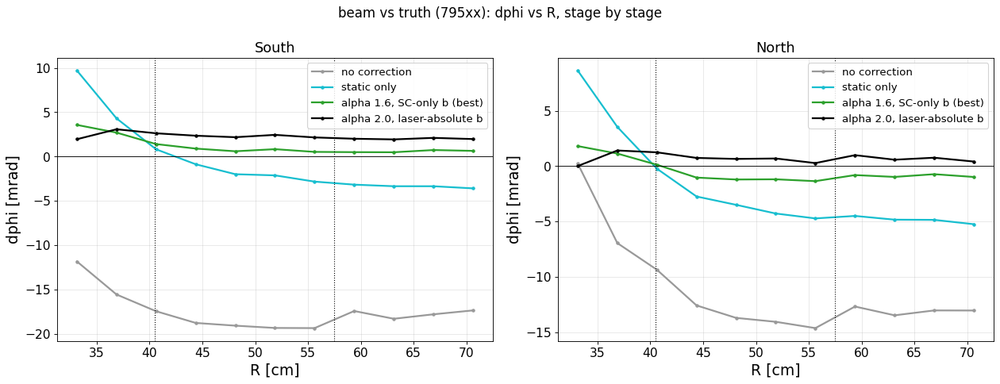

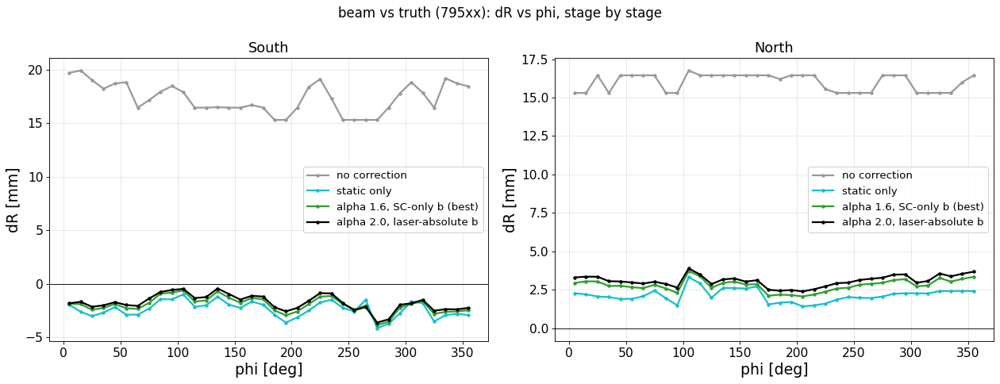

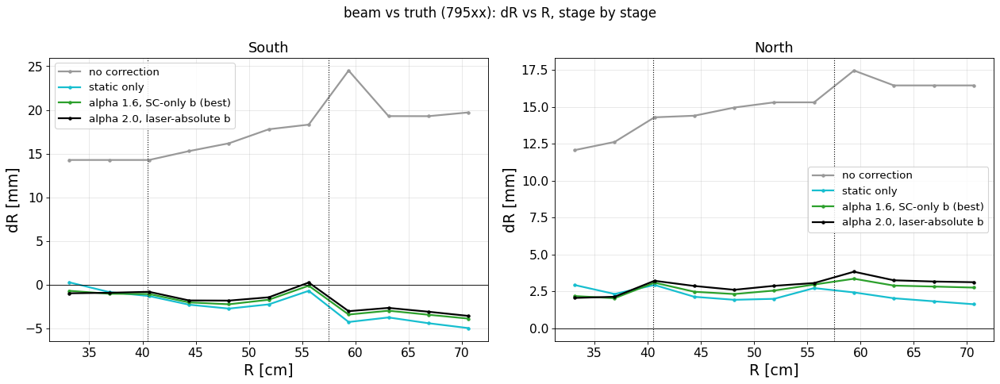

CONFIG  beam - field off (795xx): stages raw, static, sc16, final; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


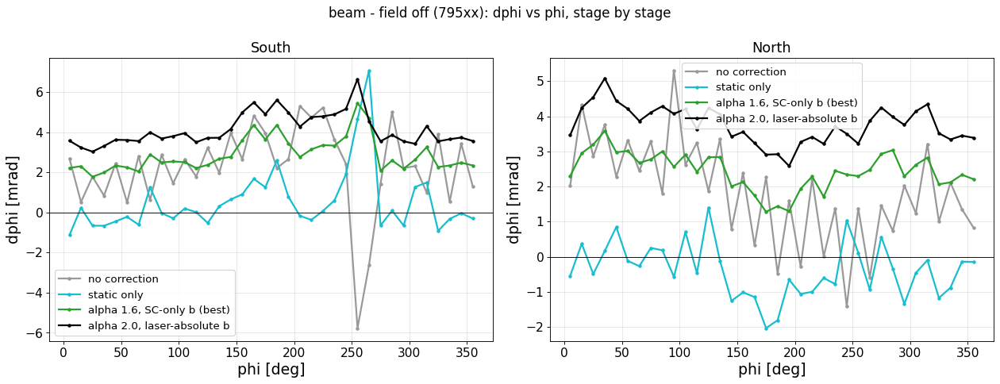

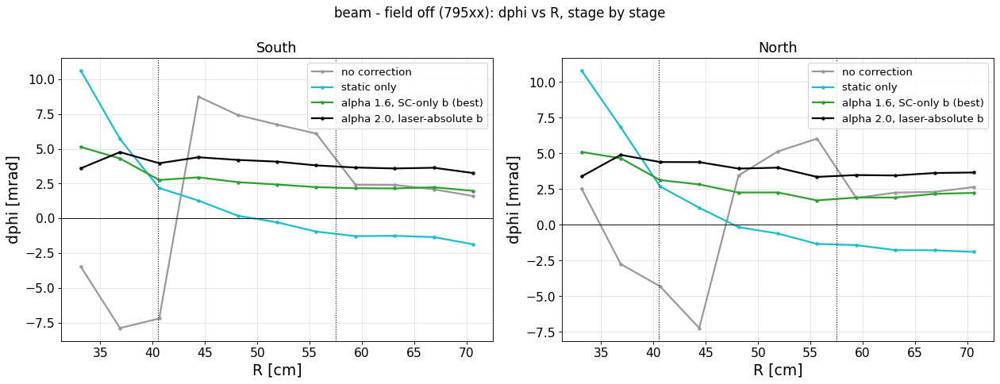

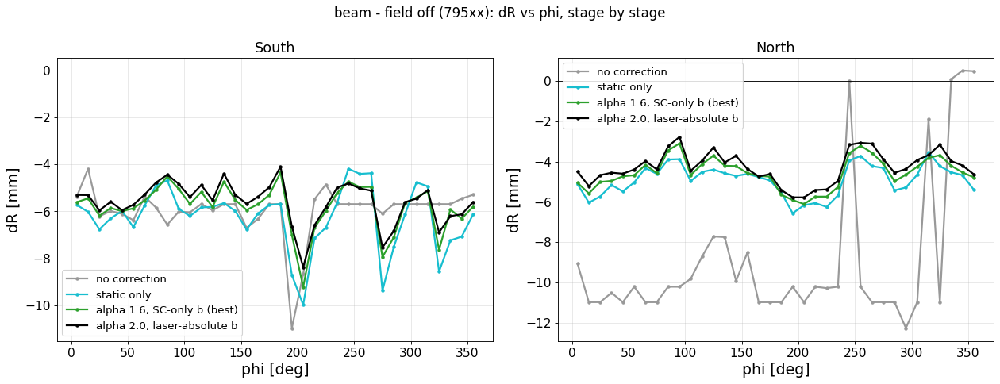

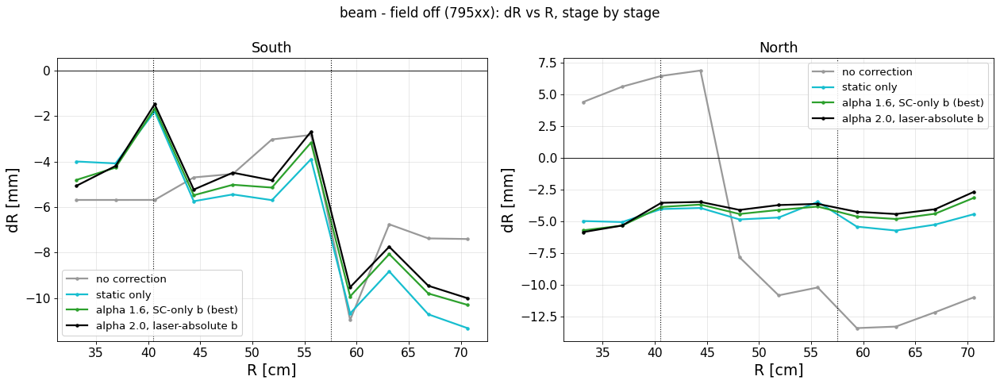

CONFIG  beam - no beam 75073 (795xx): stages raw, static, sc16, final; static = static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180)


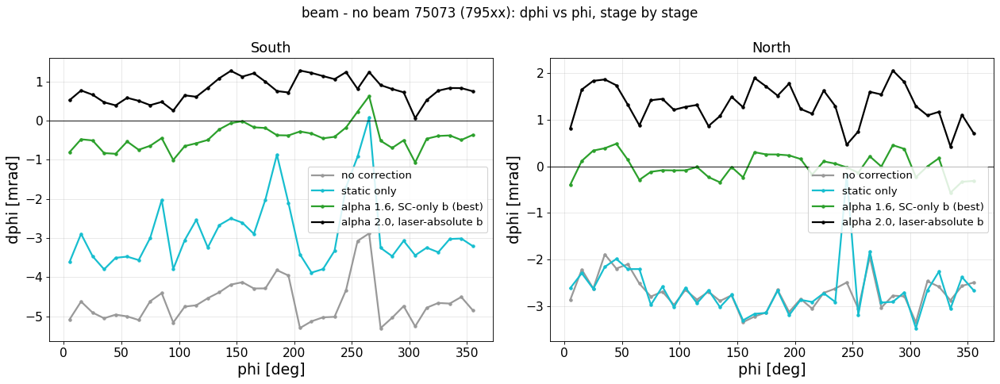

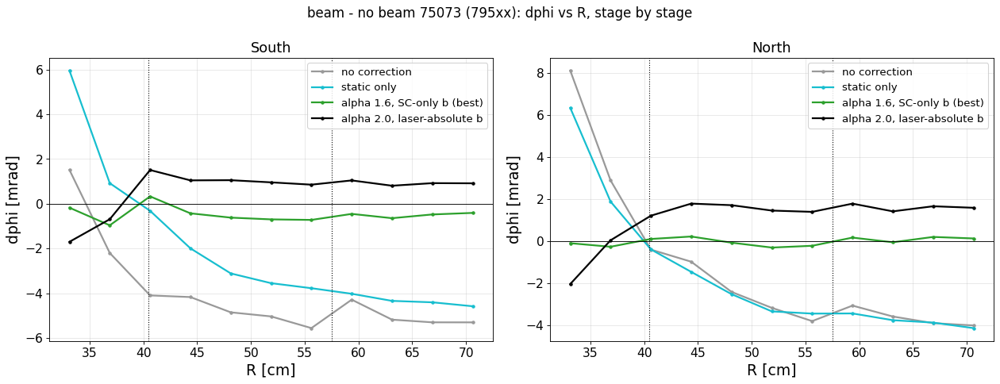

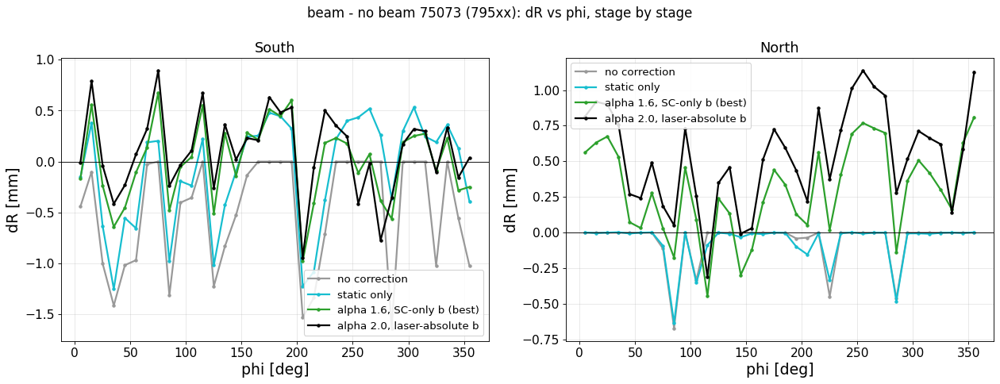

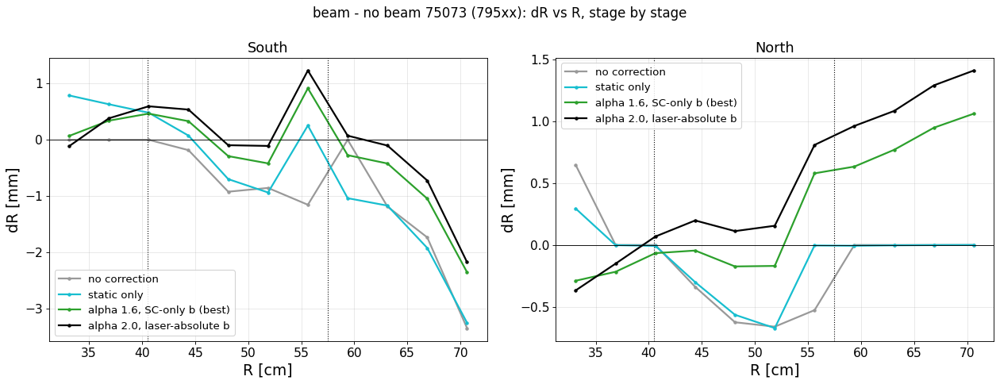

In [4]:
CASES = (('field off 78242 vs truth', 'OFFT', ['78242'], ('raw', 'static')),
         ('no beam 75073 - field off', 'NBOFF', ['75073'], ('raw', 'static')),
         ('no beam 83319 - field off', 'NBOFF', ['83319'], ('raw', 'static')),
         ('beam vs truth (795xx)', 'T', sq.LOW, ('raw', 'static', 'sc16', 'final')),
         ('beam - field off (795xx)', 'OFF', sq.LOW, ('raw', 'static', 'sc16', 'final')),
         ('beam - no beam 75073 (795xx)', 'NB75', sq.LOW, ('raw', 'static', 'sc16', 'final')))
for lab, pre, keys, sts in CASES:
    print(f'CONFIG  {lab}: stages ' + ', '.join(sts) + '; static = ' + STATIC)
    for qn in ('dphi', 'dR'):
        show(sq.stages_fig(lab, pre, keys, sts, qn, 'phi'), sq.stages_fig(lab, pre, keys, sts, qn, 'R'))

## 3. TPC tilt: does a rotation remove the sine?
The five geometries of the big scan at z −40:
- rot_x ∈ {0, 0.16, 0.32} mrad at rot_y 0.85;
- rot_y ∈ {0.65, 0.85, 1.05} mrad at rot_x 0.16.

Shown: dφ and dR vs φ with the constant removed, plus a sine fit (amplitude and phase in the legend). First no beam −
field off (static only, no space charge), then beam − field off (α 1.6 at b 0.60). A sine that changes with the
rotation is the tilt; one that stays needs something else (an x/y shift, a field-cage asymmetry, a Br scale).

CONFIG  no beam 75073 / 83319 - field off, static correction (z -40 mm, TPC rotation varied, survey x/y, P/T CM field, IFC automatic, frame -180)


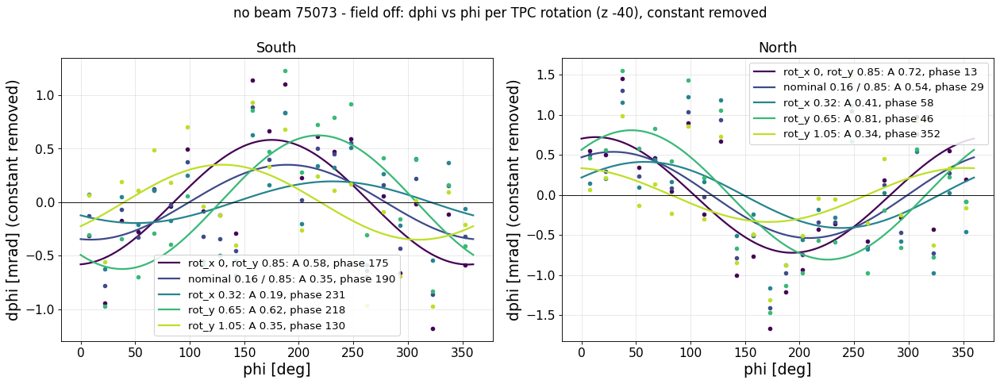

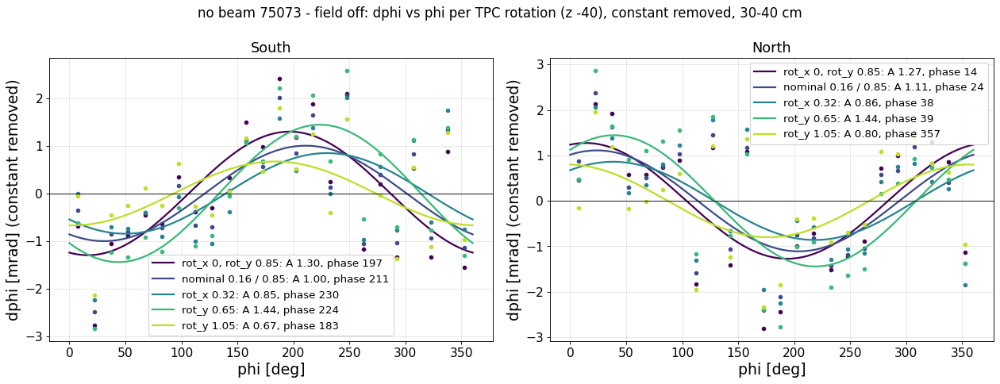

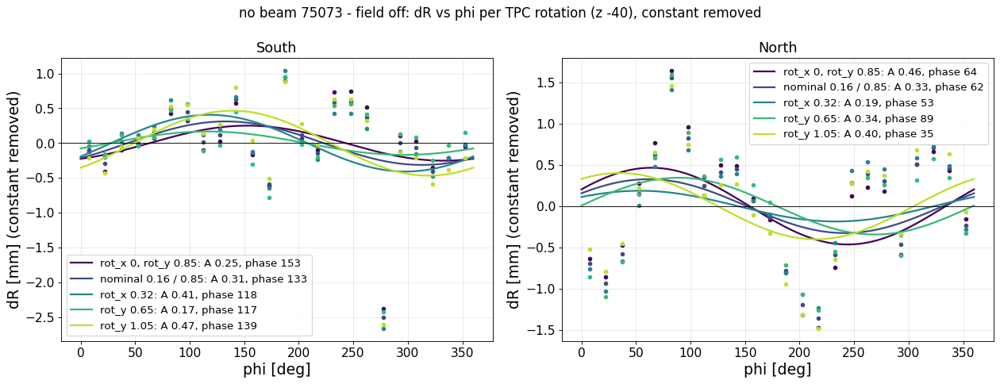

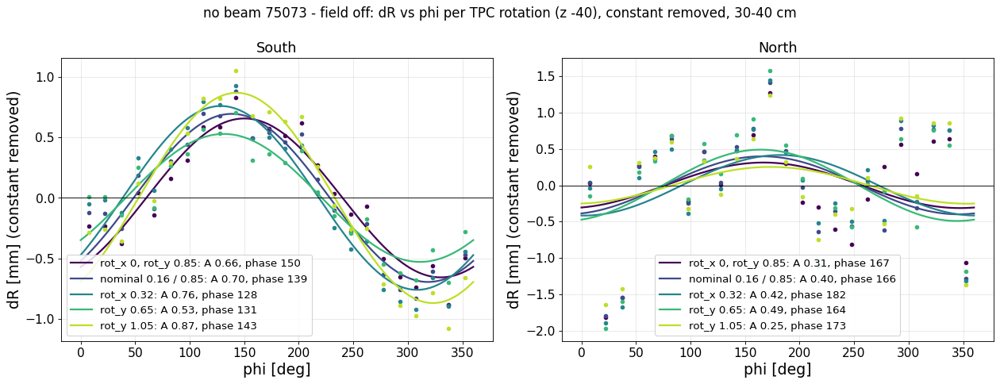

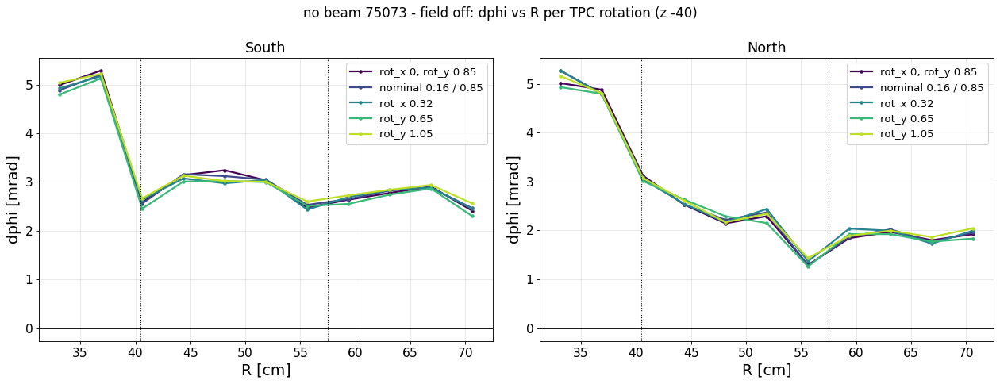

...

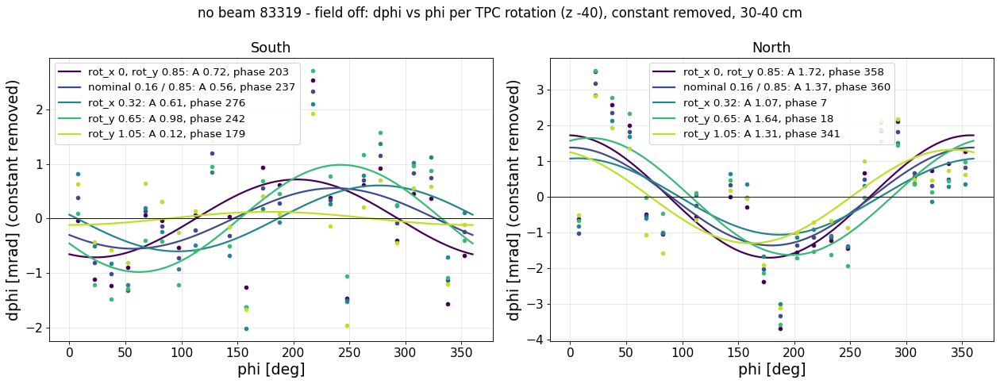

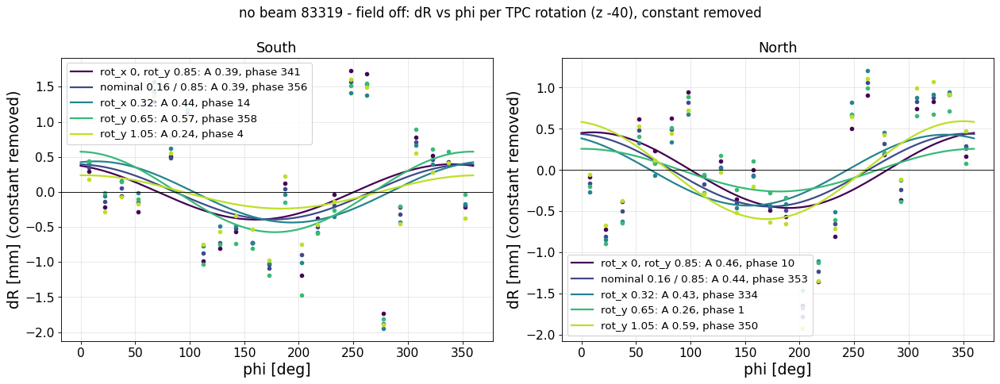

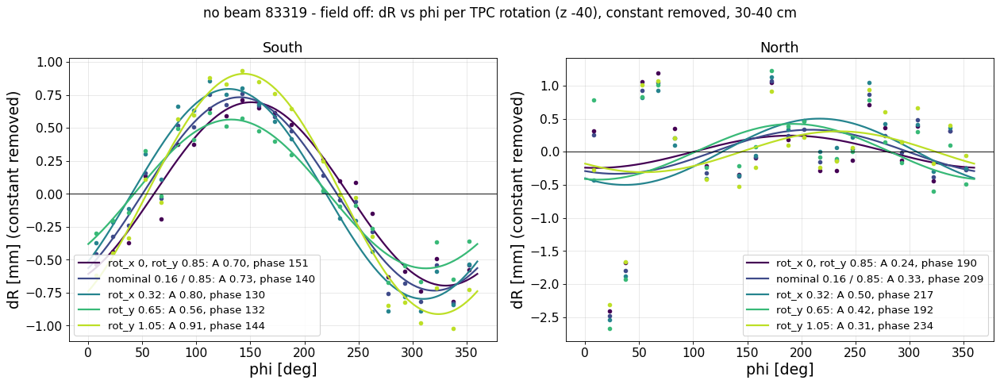

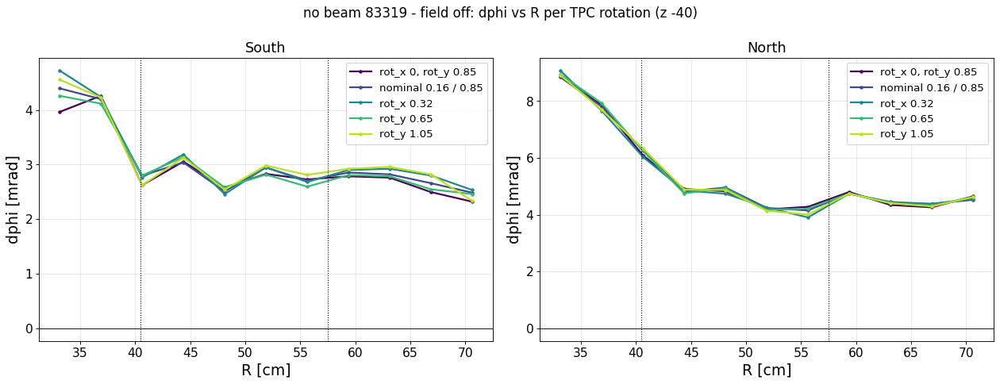

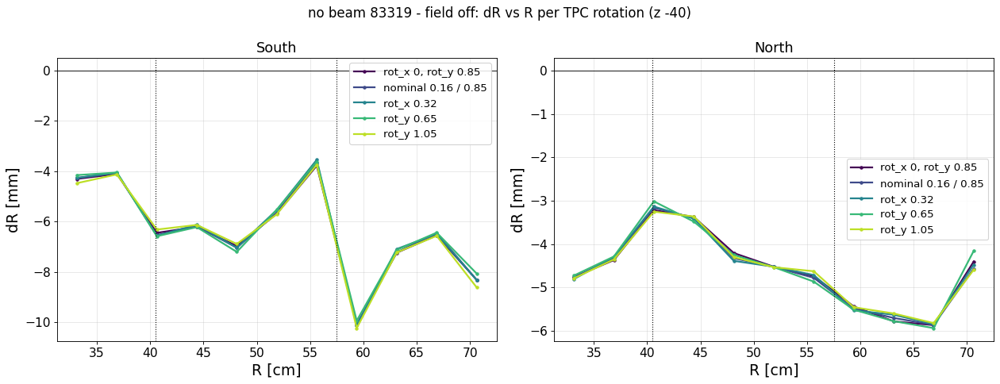

In [5]:
print('CONFIG  no beam 75073 / 83319 - field off, ' + STATIC.replace('tilt rot_x 0.16 / rot_y 0.85 mrad', 'TPC rotation varied'))
for run in ('75073', '83319'):
    for qn in ('dphi', 'dR'):
        f1, _ = sq.tilt_fig('OFF', [run], 'st_nom', qn, f'no beam {run} - field off')
        f2, _ = sq.tilt_fig('OFF', [run], 'st_nom', qn, f'no beam {run} - field off', rmin=30, rmax=40.5)
        show(f1, f2)
    show(sq.tilt_r_fig('OFF', [run], 'st_nom', 'dphi', f'no beam {run} - field off'), sq.tilt_r_fig('OFF', [run], 'st_nom', 'dR', f'no beam {run} - field off'))

CONFIG  beam 795xx - field off, alpha 1.6 map at b 0.60 (keff = 0.60 x I_side), TPC rotation varied, z -40


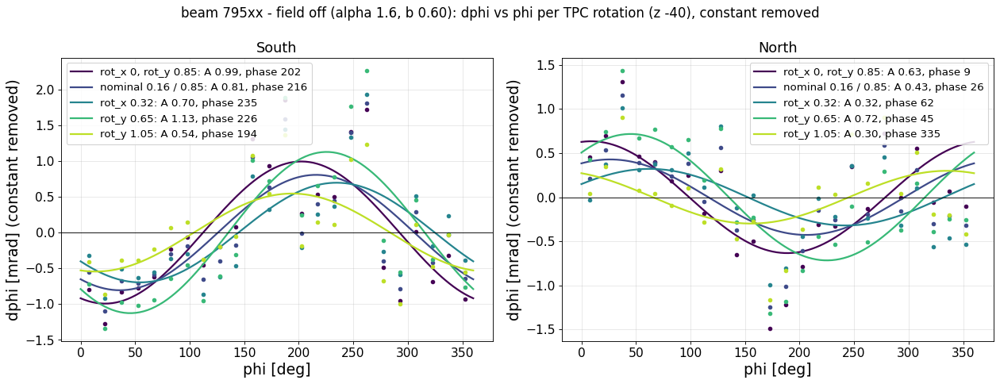

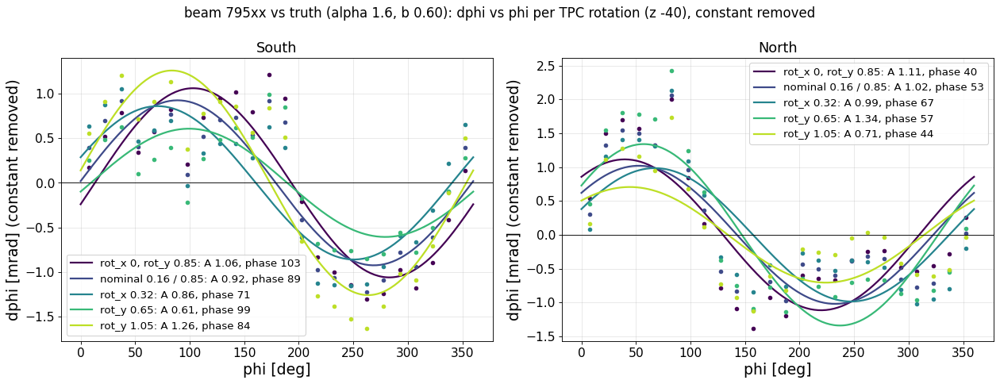

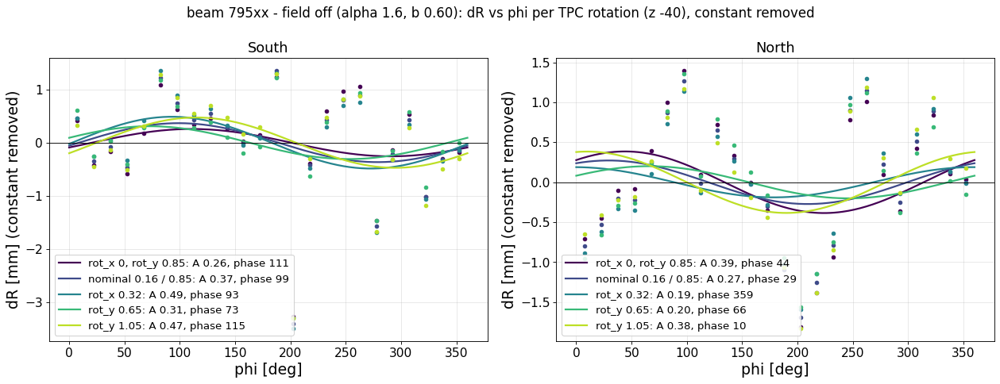

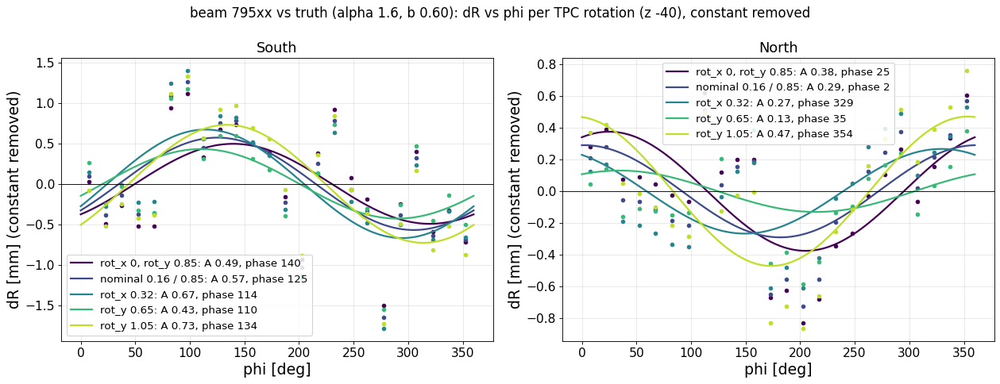

CONFIG  first-harmonic amplitude per geometry and module ring


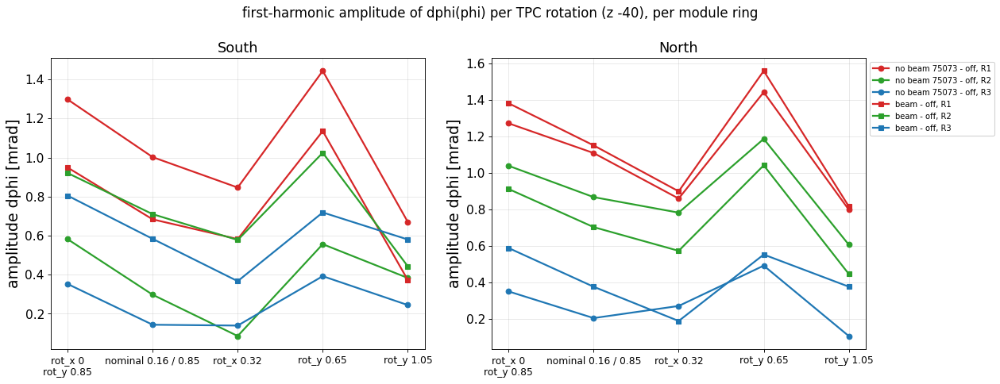

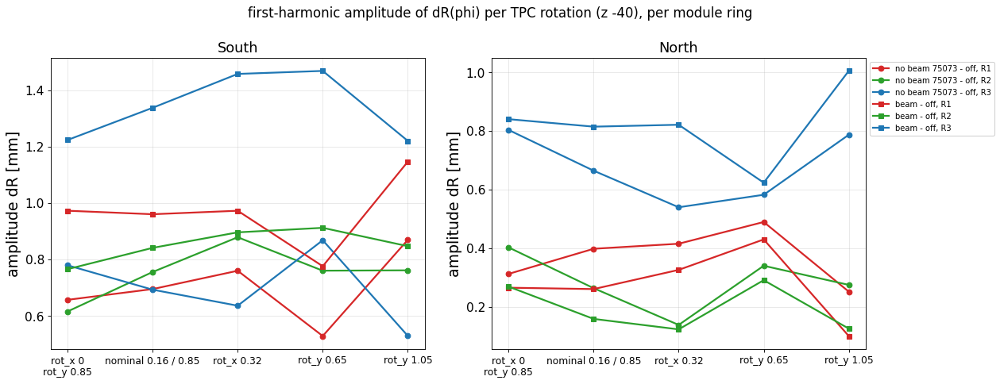

In [6]:
print('CONFIG  beam 795xx - field off, alpha 1.6 map at b 0.60 (keff = 0.60 x I_side), TPC rotation varied, z -40')
beam = ['79508', '79513', '79516', '79529']
for qn in ('dphi', 'dR'):
    f1, _ = sq.tilt_fig('OFF', beam, 'prod1p6_b600', qn, 'beam 795xx - field off (alpha 1.6, b 0.60)')
    f2, _ = sq.tilt_fig('T', beam, 'prod1p6_b600', qn, 'beam 795xx vs truth (alpha 1.6, b 0.60)')
    show(f1, f2)
print('CONFIG  first-harmonic amplitude per geometry and module ring')
show(sq.tilt_amp_summary([('OFF', ['75073'], 'st_nom', 'no beam 75073 - off'), ('OFF', beam, 'prod1p6_b600', 'beam - off')], 'dphi'),
     sq.tilt_amp_summary([('OFF', ['75073'], 'st_nom', 'no beam 75073 - off'), ('OFF', beam, 'prod1p6_b600', 'beam - off')], 'dR'))

## 4. TPC z shift
The big scan B at z −60 … −10 (nominal tilt; z −40 from the tilt re-extraction). Shown: dφ and dR vs R per z, for no
beam − field off and for beam − field off (α 1.6, b 0.60). Then RΔφ vs φ per z (R2 rings, sector medians) with the
sine amplitude.

CONFIG  no beam 75073 - field off, static only, TPC z varied (tilt 0.16 / 0.85)


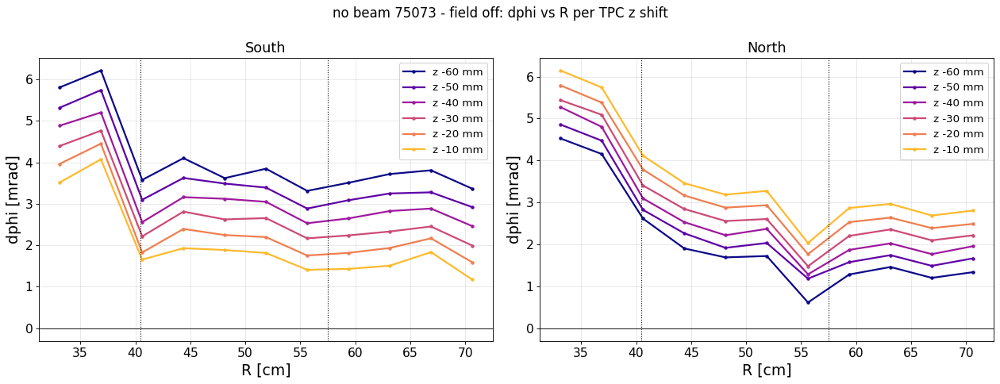

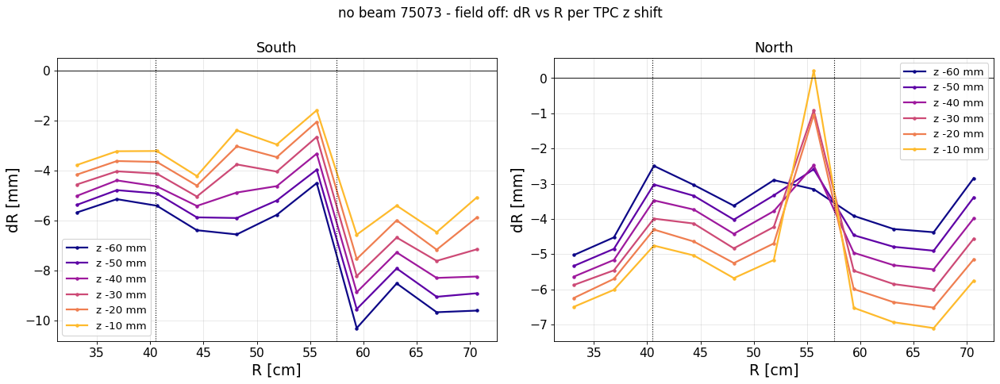

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/staticqa.py:189: RuntimeWarning: Mean of empty slice
  PS = np.nanmean([x[3] for x in vals], axis=0)


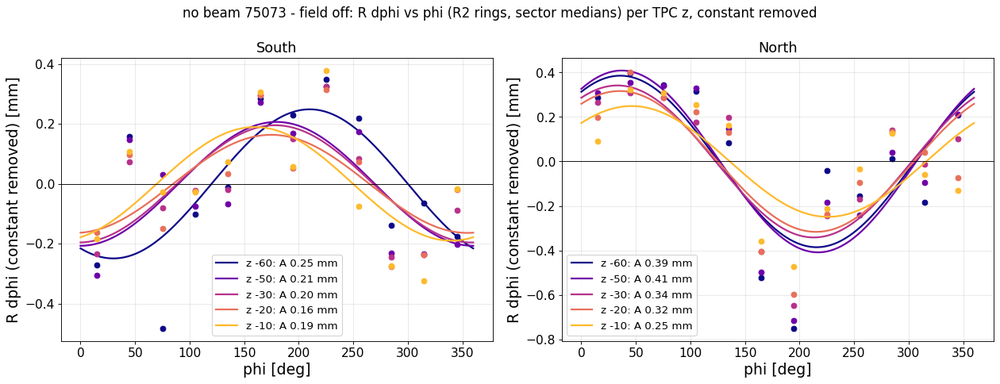

CONFIG  beam 79513 - field off, alpha 1.6 at b 0.60, TPC z varied


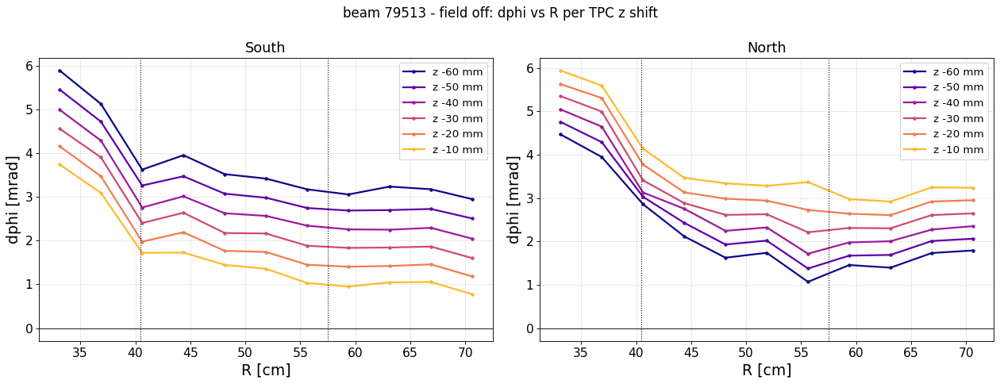

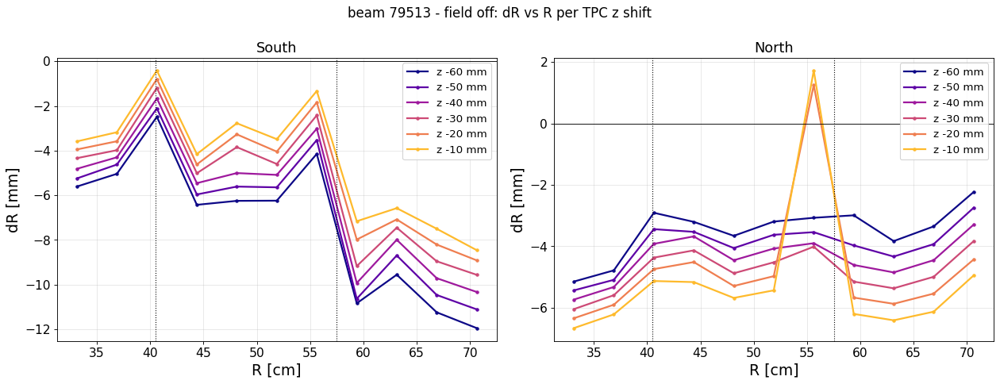

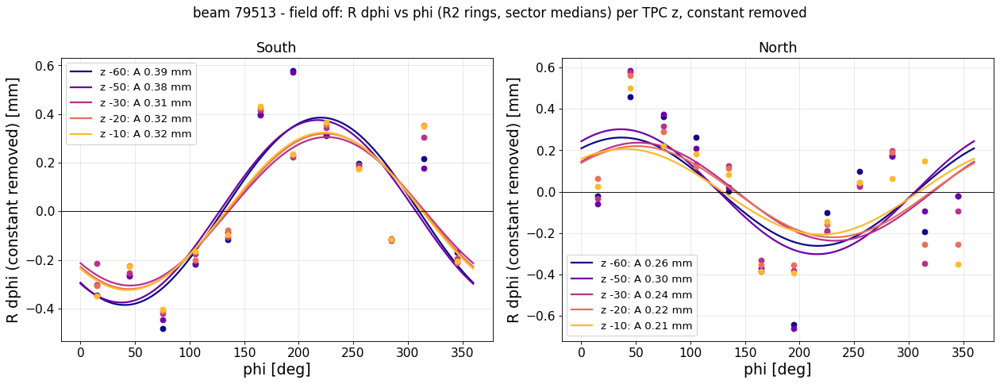

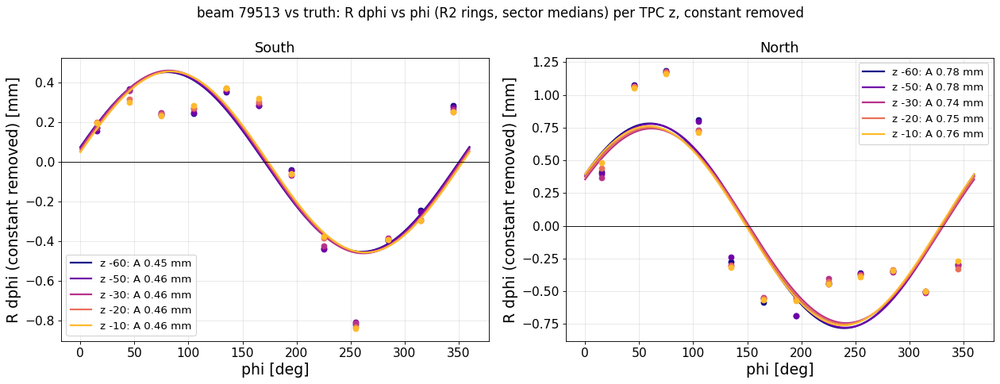

In [7]:
print('CONFIG  no beam 75073 - field off, static only, TPC z varied (tilt 0.16 / 0.85)')
show(sq.z_fig(75073, 'st_nom', 0.0, 0, 'dphi', 'no beam 75073 - field off'), sq.z_fig(75073, 'st_nom', 0.0, 0, 'dR', 'no beam 75073 - field off'))
show(sq.z_phi_fig(75073, 'st_nom', 0.0, 0, 'no beam 75073 - field off'))
print('CONFIG  beam 79513 - field off, alpha 1.6 at b 0.60, TPC z varied')
show(sq.z_fig(79513, 'prod1p6', 0.6, 0, 'dphi', 'beam 79513 - field off'), sq.z_fig(79513, 'prod1p6', 0.6, 0, 'dR', 'beam 79513 - field off'))
show(sq.z_phi_fig(79513, 'prod1p6', 0.6, 0, 'beam 79513 - field off'), sq.z_phi_fig(79513, 'prod1p6', 0.6, 1, 'beam 79513 vs truth'))

## 5. Magnetic-field scale: B_r and B_z (PHGarfield::SetMagneticFieldScale, patch 0005)
Static model as above (z −40, tilt 0.16 / 0.85). B_r × {0.5, 0.8, 0.9, 1.1, 1.2, 1.5} and B_z × {0.99, 1.01}, same
scale on both sides, applied in the TPC frame (B_φ unchanged).
- No beam 75073 / 83319: static only.
- Beam: 795xx, α 1.6 at the space-charge b 0.60.

B_r × 1.5 breaks the matching (residuals jump around) and is dropped from the plots. If B_r is the missing piece, no beam −
field off (cyan / purple) and beam − field off (green) should go flat and to zero together.

CONFIG  static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r / B_z scale | beam: alpha 1.6, keff = 0.60 x I_side


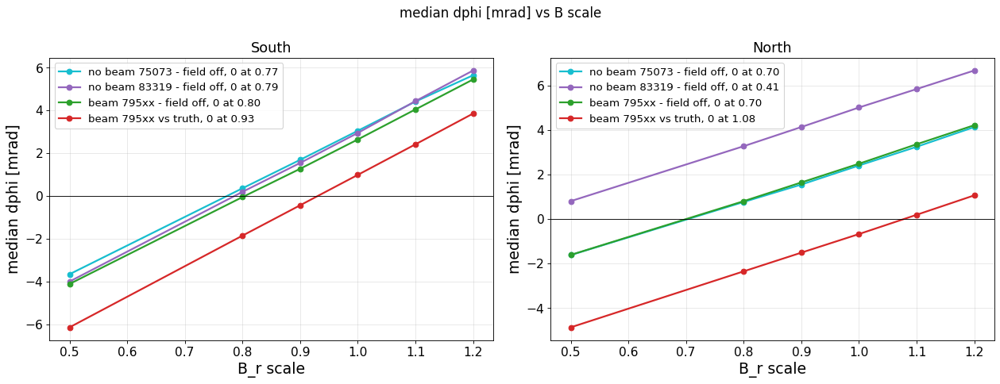

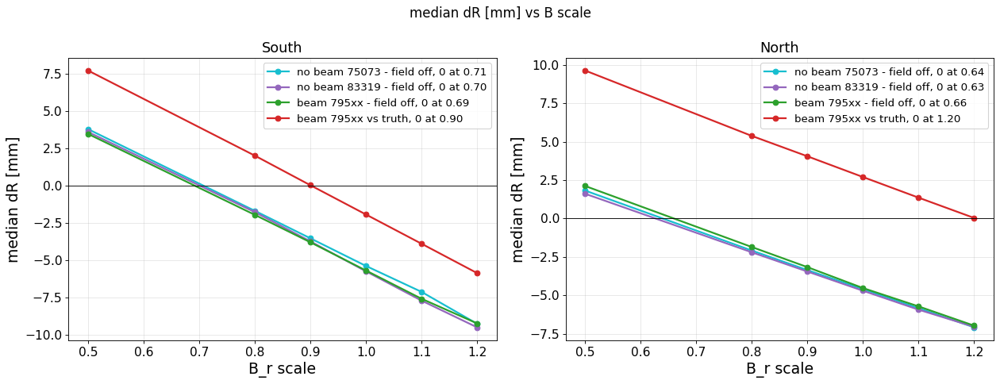

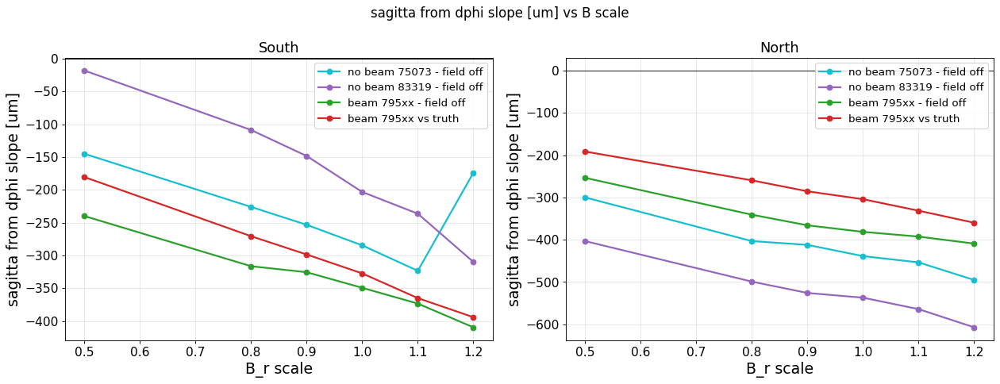

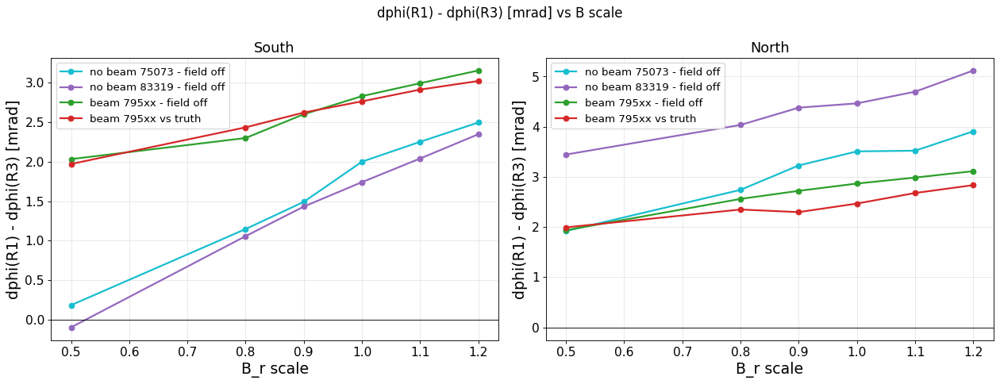

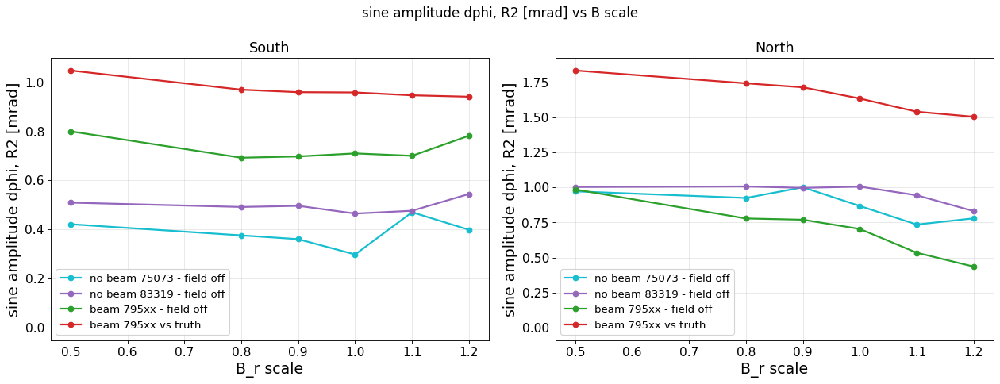

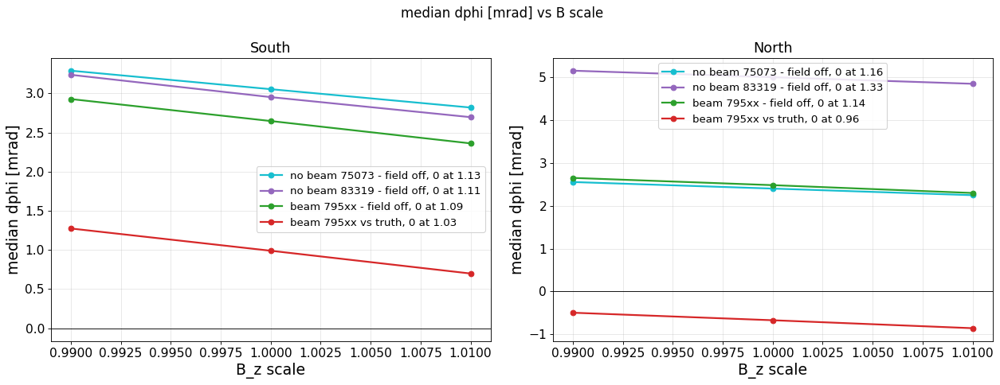

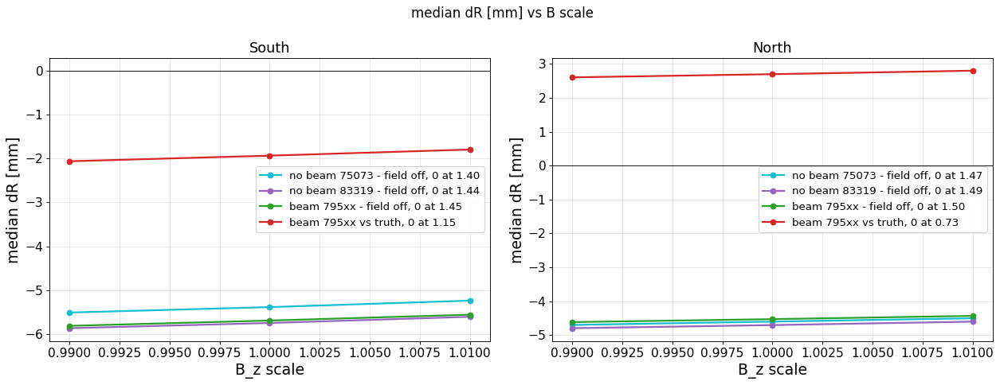

In [8]:
print('CONFIG  ' + STATIC + ' + B_r / B_z scale | beam: alpha 1.6, keff = 0.60 x I_side')
for key in ('dphi', 'dR', 'sag', 'd13', 'amp'):
    show(sq.bs_summary(key))
show(sq.bs_summary('dphi', scan=sq.BZ), sq.bs_summary('dR', scan=sq.BZ))

CONFIG  no beam 75073 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale


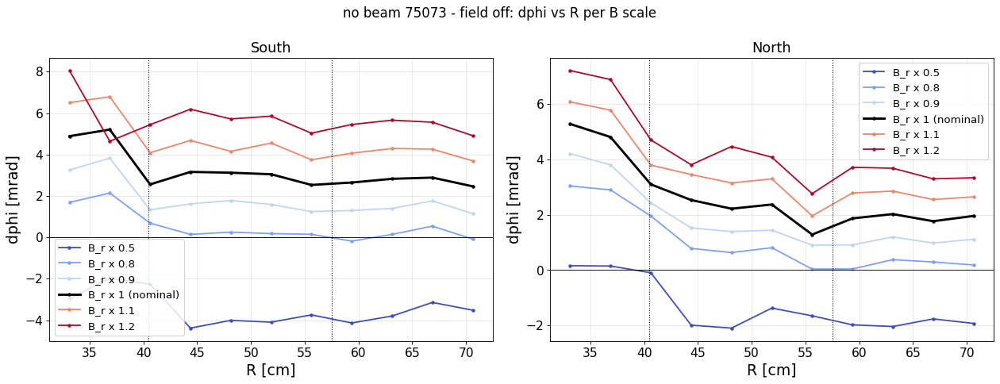

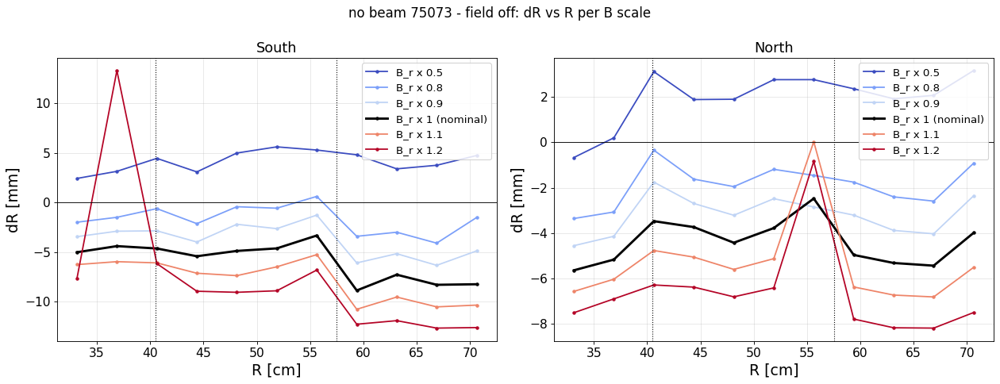

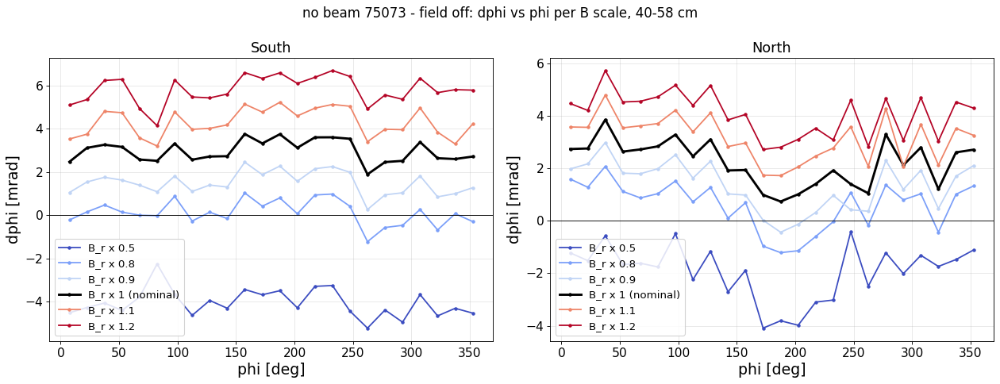

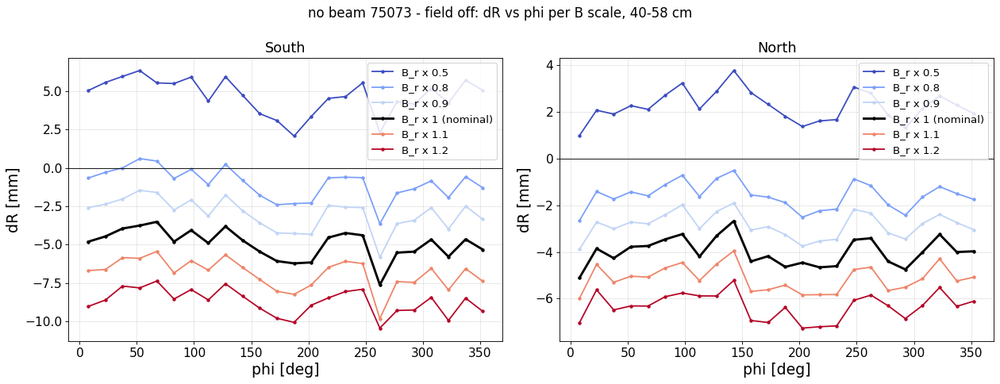

CONFIG  no beam 83319 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale


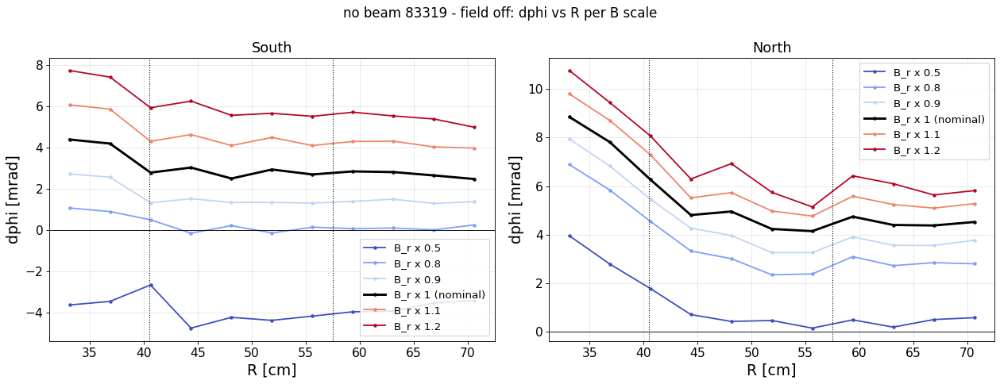

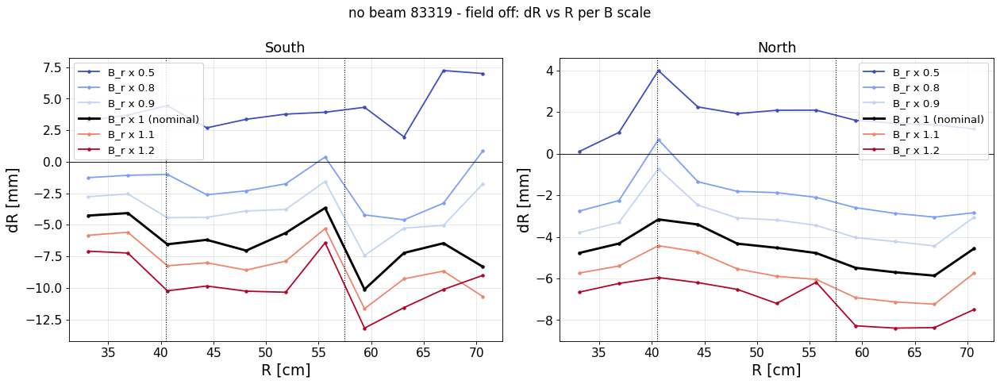

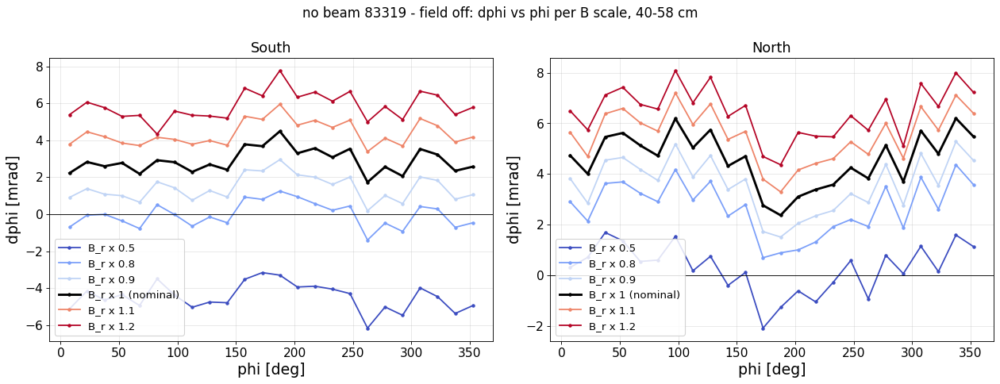

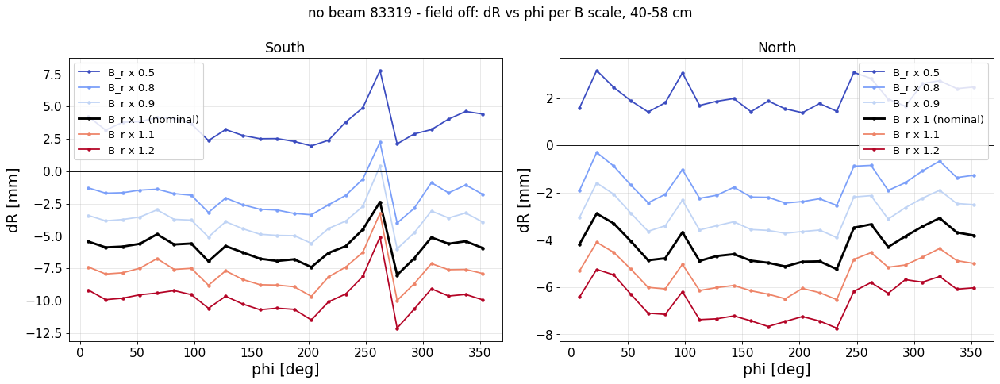

CONFIG  beam 795xx - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale | alpha 1.6, keff = 0.60 x I_side


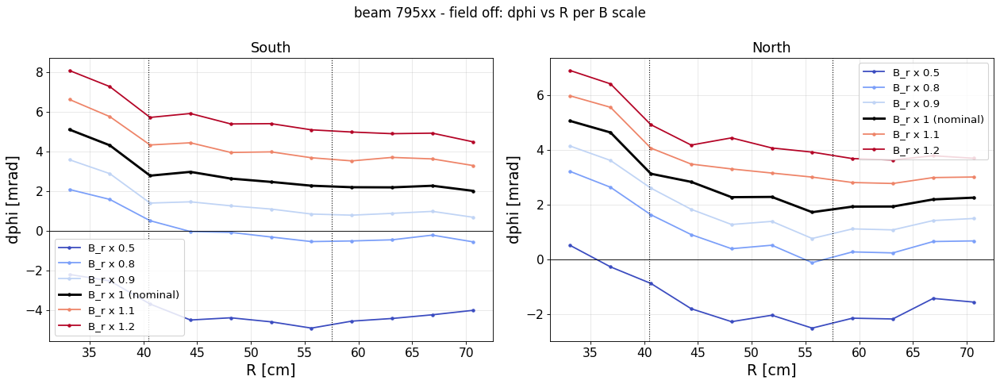

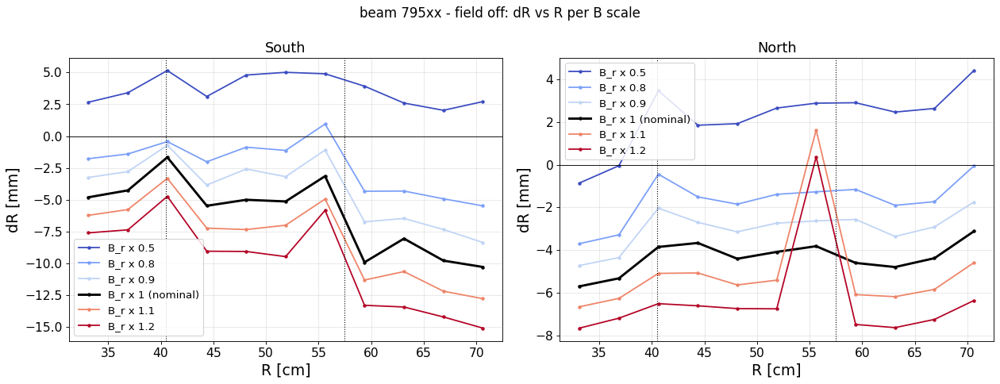

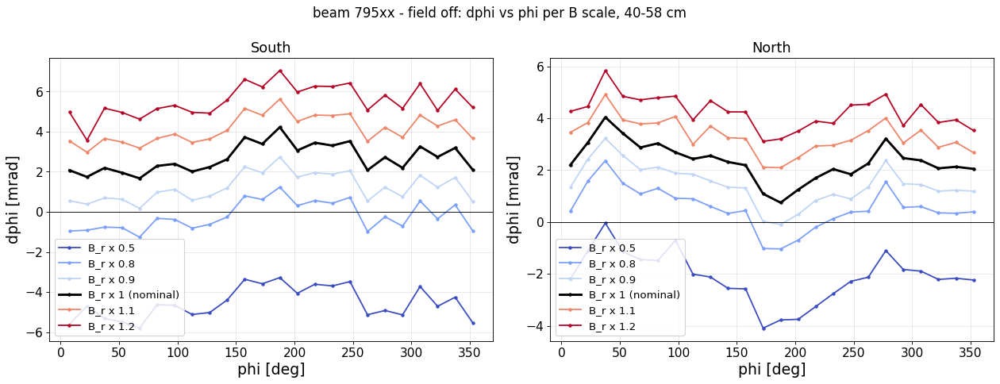

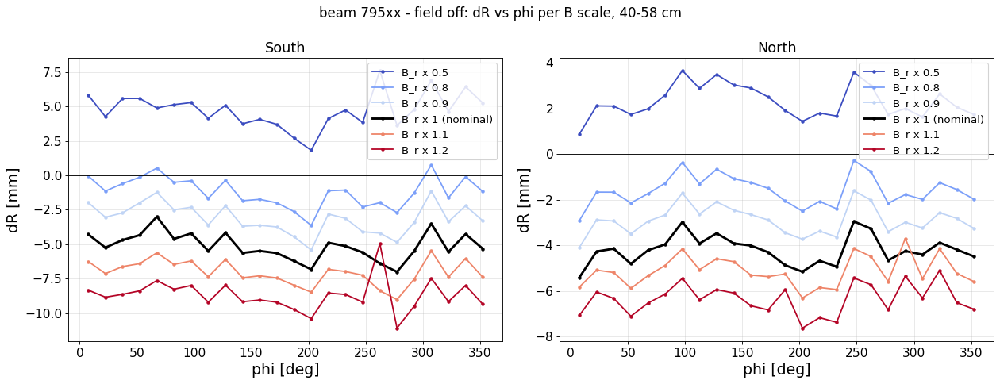

CONFIG  beam 795xx vs truth: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale | alpha 1.6, keff = 0.60 x I_side


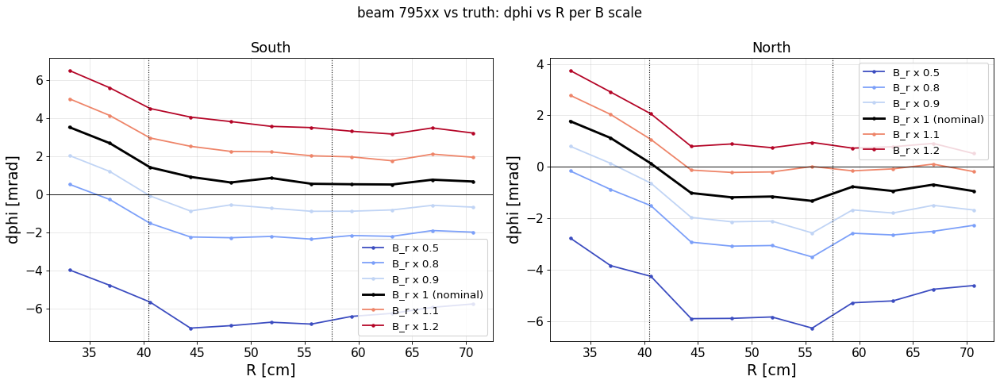

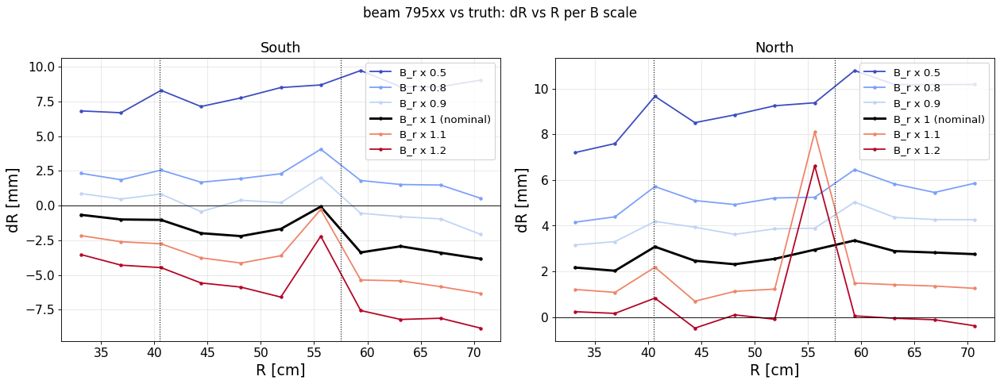

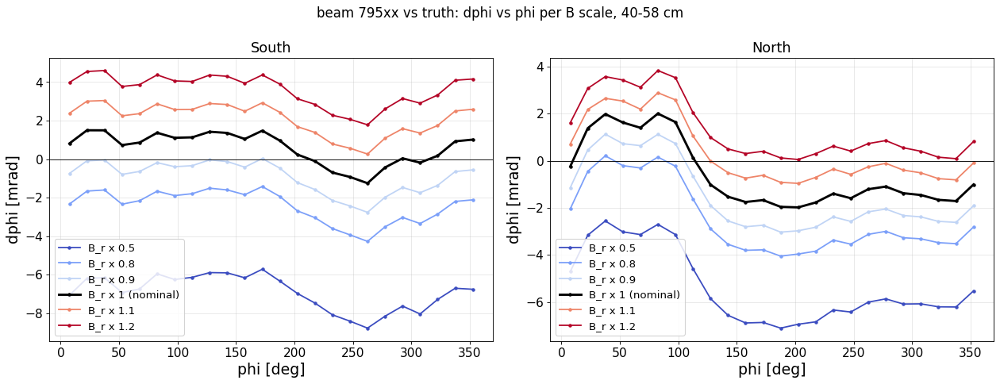

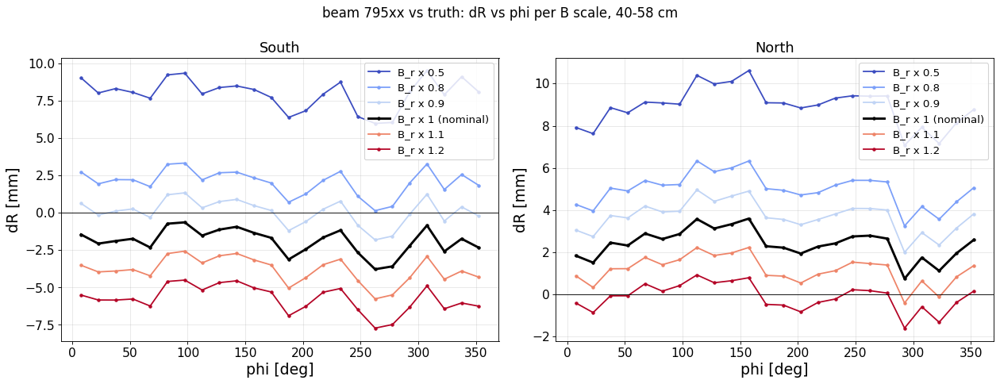

In [9]:
for lab, ref, runs, pre in sq.BS_CASES:
    print(f'CONFIG  {lab}: ' + STATIC + ' + B_r scale' + (' | alpha 1.6, keff = 0.60 x I_side' if pre == 'a1p6' else ''))
    show(sq.bs_fig(ref, runs, pre, 'dphi', 'R', lab), sq.bs_fig(ref, runs, pre, 'dR', 'R', lab))
    show(sq.bs_fig(ref, runs, pre, 'dphi', 'phi', lab, rmin=40.5, rmax=57.5), sq.bs_fig(ref, runs, pre, 'dR', 'phi', lab, rmin=40.5, rmax=57.5))

CONFIG  static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_z scale (0.99 / 1.01)


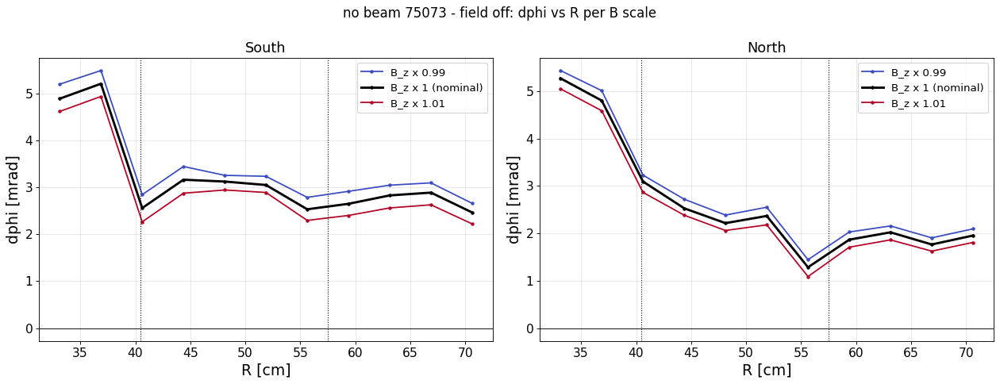

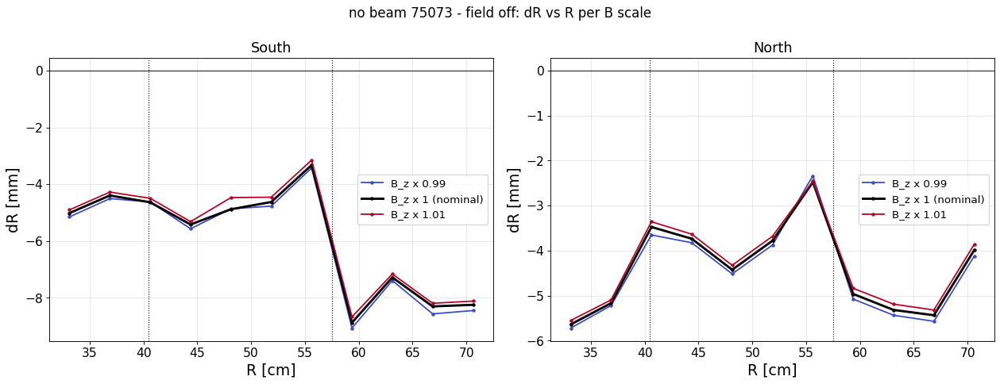

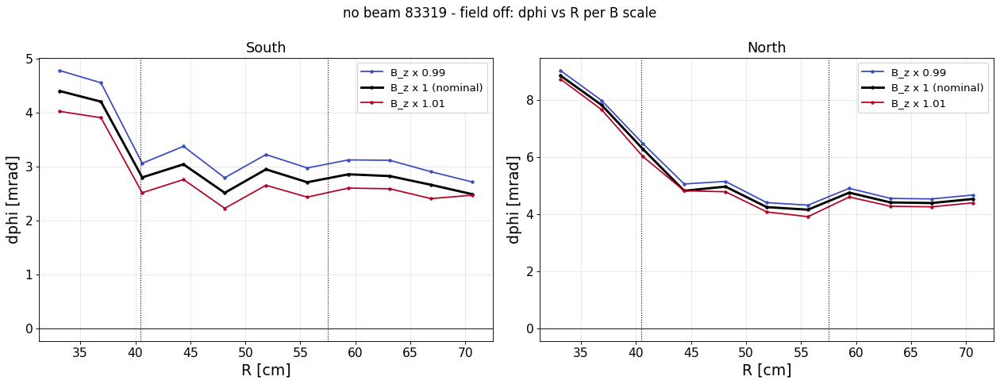

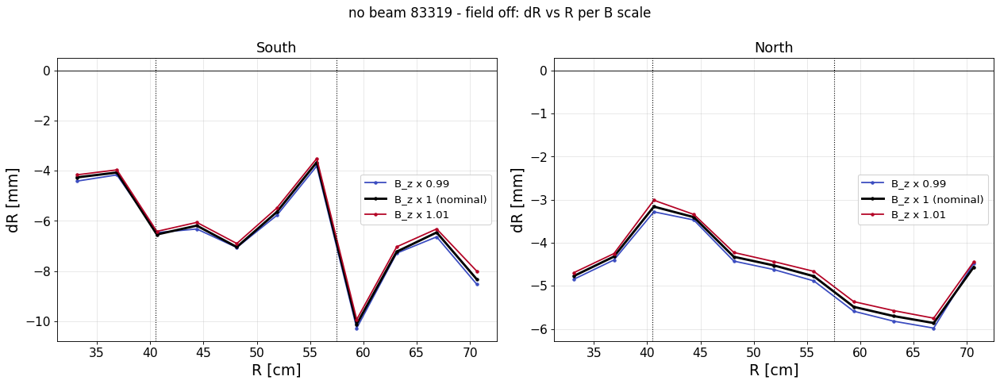

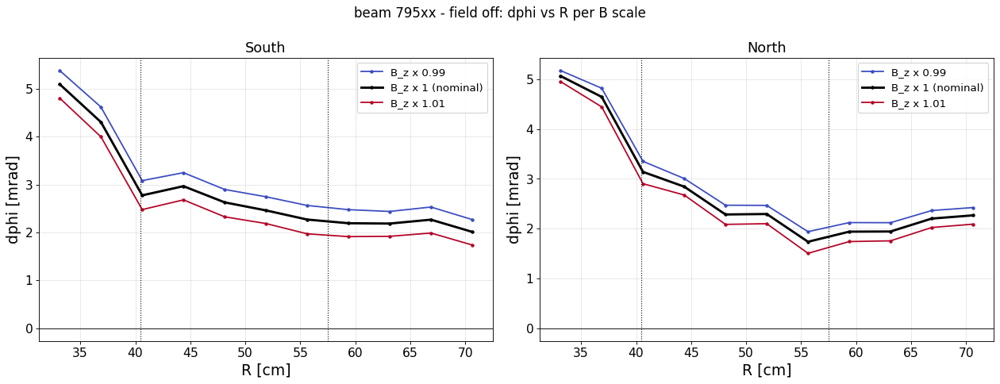

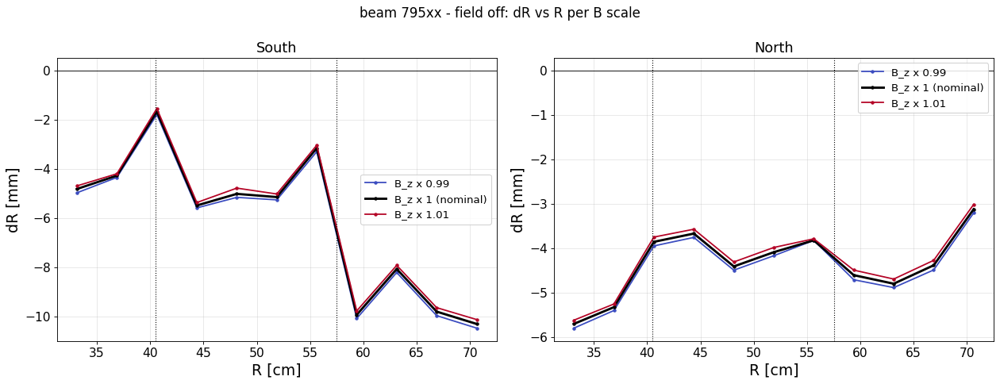

In [10]:
print('CONFIG  ' + STATIC + ' + B_z scale (0.99 / 1.01)')
for lab, ref, runs, pre in sq.BS_CASES[:3]:
    show(sq.bs_fig(ref, runs, pre, 'dphi', 'R', lab, scan=sq.BZ), sq.bs_fig(ref, runs, pre, 'dR', 'R', lab, scan=sq.BZ))

### What the B scale does
- **B_r moves the two offsets together.** Per +0.1 in the B_r scale:
  - median dφ +1.35 mrad (South) / +0.83 mrad (North);
  - median dR −1.85 mm (South) / −1.27 mm (North);
  - ratio dR / RΔφ ≈ 3, the E×B (ωτ) signature.
- **Both offsets cross 0 near B_r ≈ 0.7–0.8 on both sides**, identically for no beam − field off and beam − field off:
  - dφ = 0 at 0.77–0.80 South, 0.70 North (83319 North is offset by ~2.6 mrad and extrapolates lower);
  - dR = 0 at 0.69–0.71 South, 0.63–0.66 North.

  The −5 mm dR and +3 mrad dφ of the static model look like a B_r effect that is ~25–30 % too strong. The space-charge
  part is untouched: beam − field off follows no beam − field off at every scale.
- **The shape is only partly B_r:**
  - sagitta −285 → −220 µm South (75073), −440 → −370 µm North;
  - the R1 step (dφ jump at 40.5 cm) halves in South but remains;
  - the R2 first harmonic (sine) doesn't change: that is the tilt, not B_r.
- **B_z ± 1 % does almost nothing** (dφ ∓0.25 mrad, dR ∓0.15 mm).
- What the scan really measures is the product ωτ · B_r. A field-map B_r that is too large, a magnet / TPC z offset
  (which would act with opposite sign on the two sides, which we do **not** see), or a drift-gas ωτ / mobility error are
  degenerate here. Tracks (rDCA) are needed to separate them.

## 6. B_r × IFC: curing the dφ(R) shape
B_r alone only shifts dφ by a constant. Near the axis B_r ∝ R, so RΔφ ∝ R and dφ moves the same at every R. The R1
excess follows the IFC voltage (big scan B, ±60 V). Grid: B_r × {0.70, 0.75, 0.80} × IFC offset
{0, −60, −90, −120, −180} V on both sides, relative to the run's automatic IFC (75073: 0 / 0; 83319, 795xx: +211 / 0).
Sides are independent.

Maps:
- rms of the ring dφ;
- the shape dφ(R1) − dφ(R2,R3);
- mean dφ;
- mean dR.

Then the dφ / dR curves per IFC offset.

CONFIG  no beam 75073 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale x IFC offset


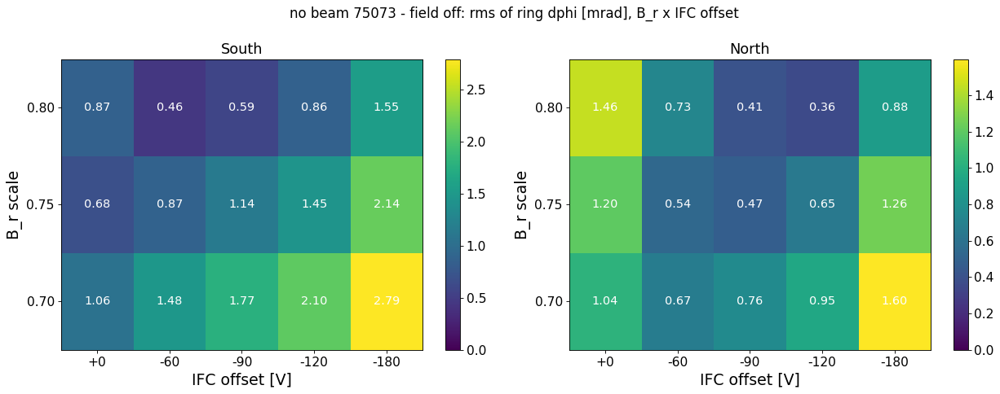

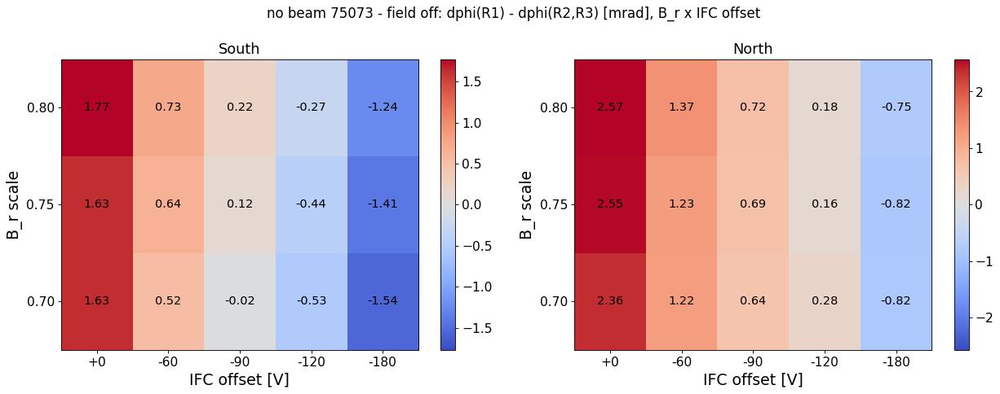

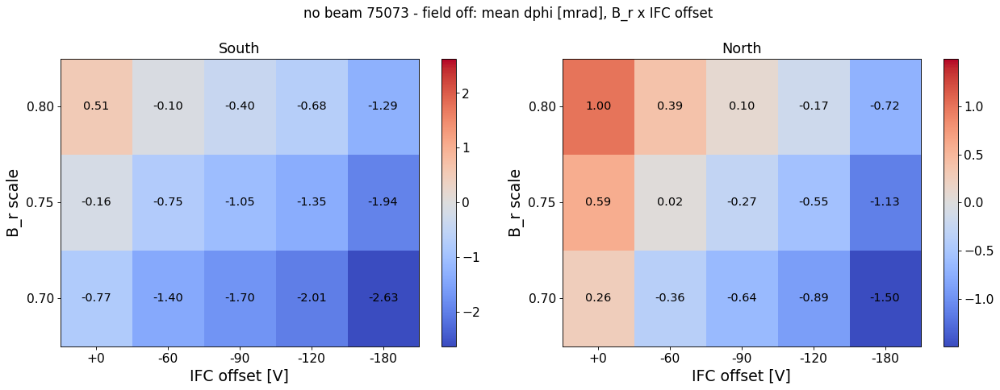

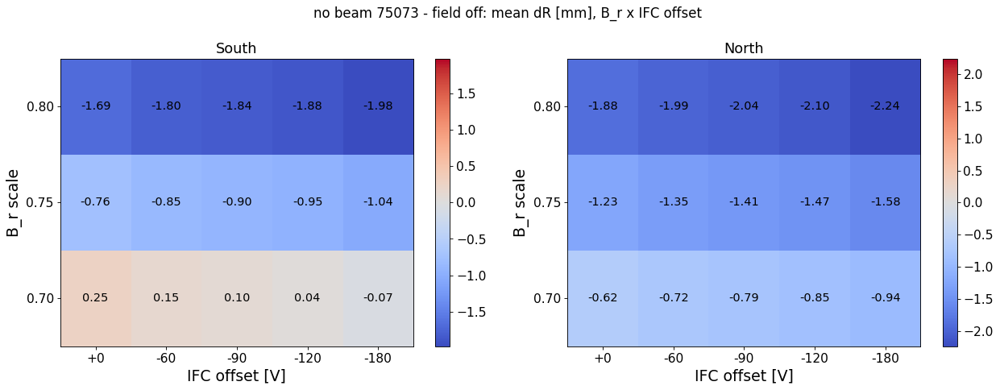

CONFIG  no beam 83319 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale x IFC offset


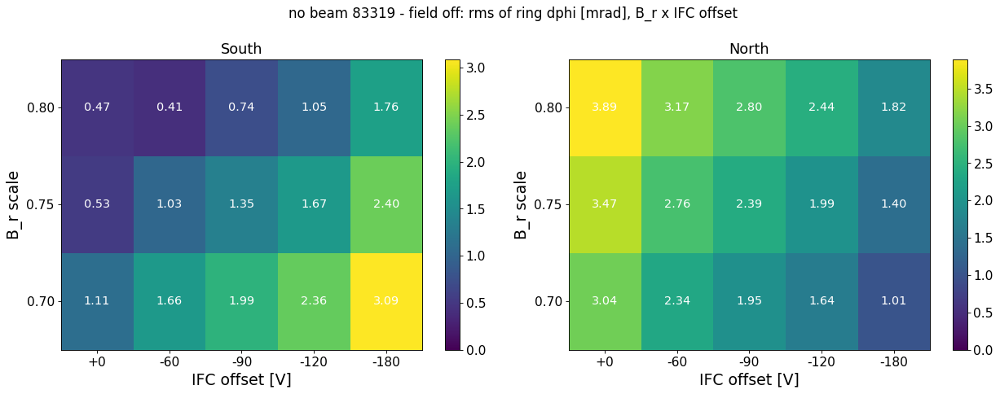

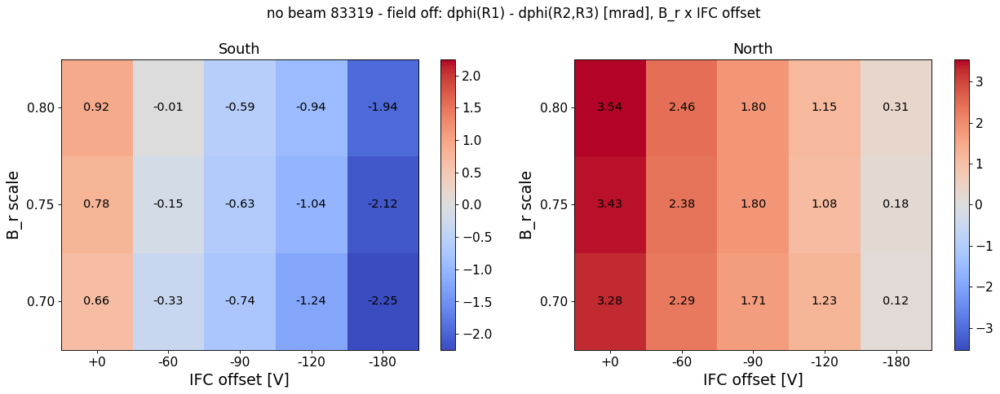

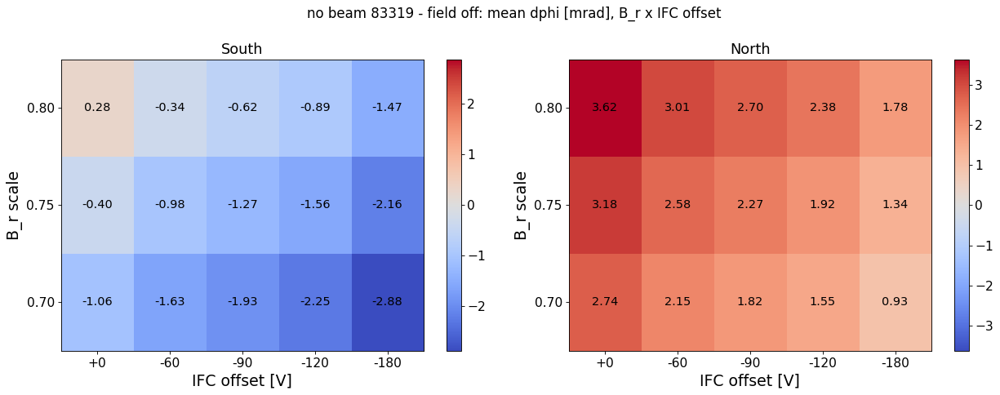

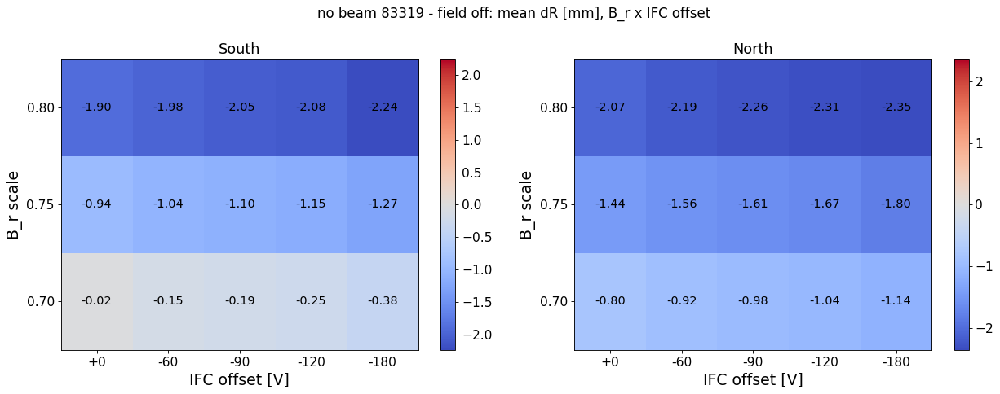

CONFIG  beam 795xx - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale x IFC offset | alpha 1.6, keff = 0.60 x I_side


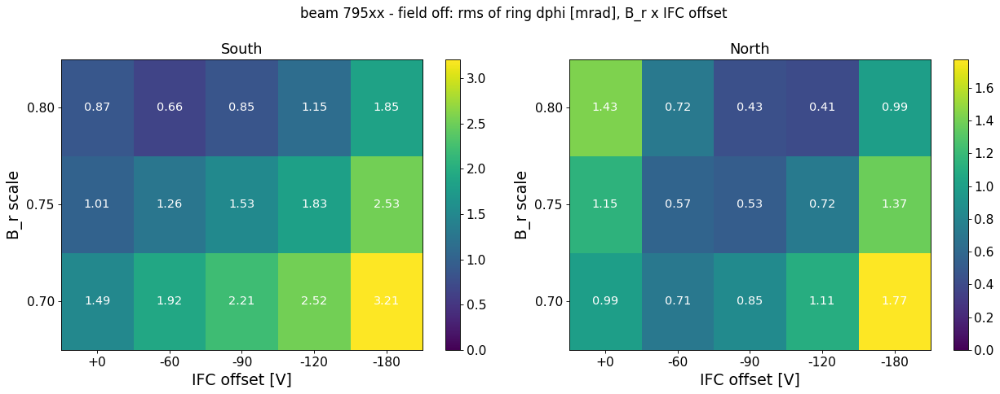

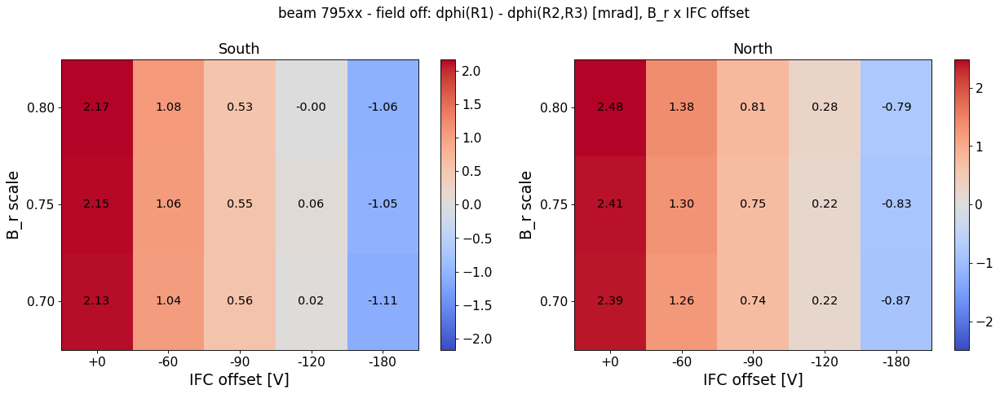

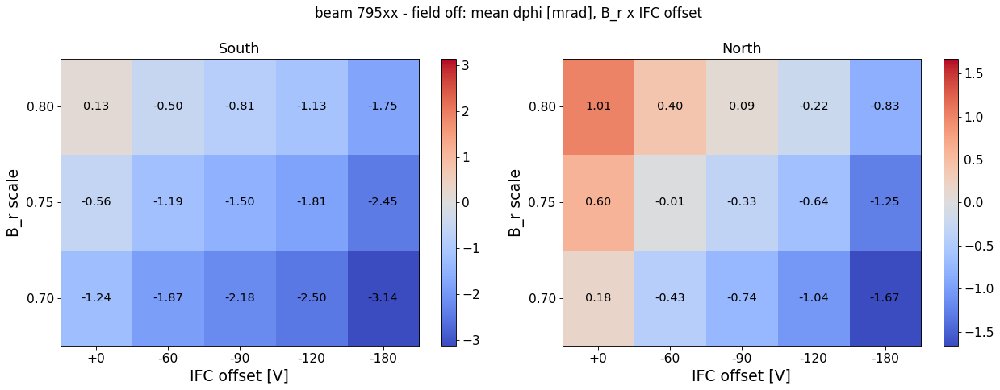

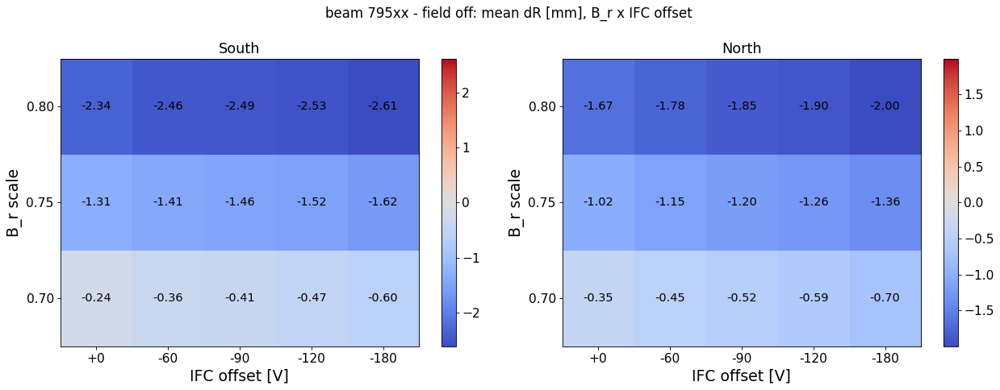

CONFIG  beam 795xx vs truth: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r scale x IFC offset | alpha 1.6, keff = 0.60 x I_side


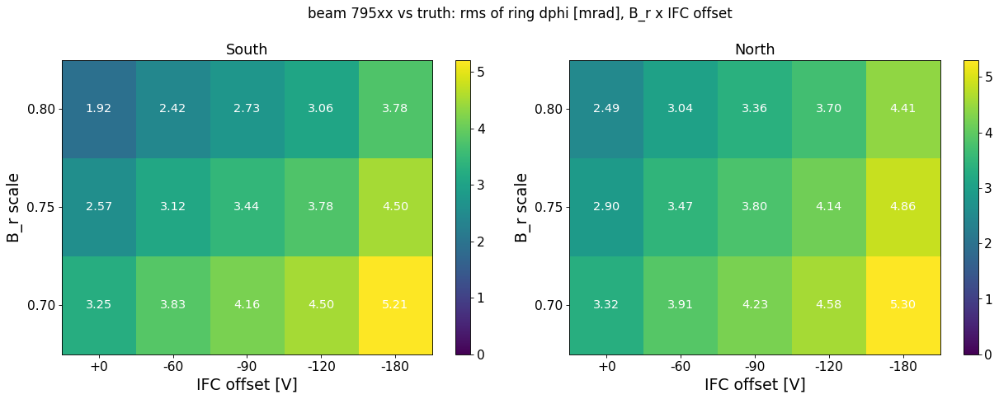

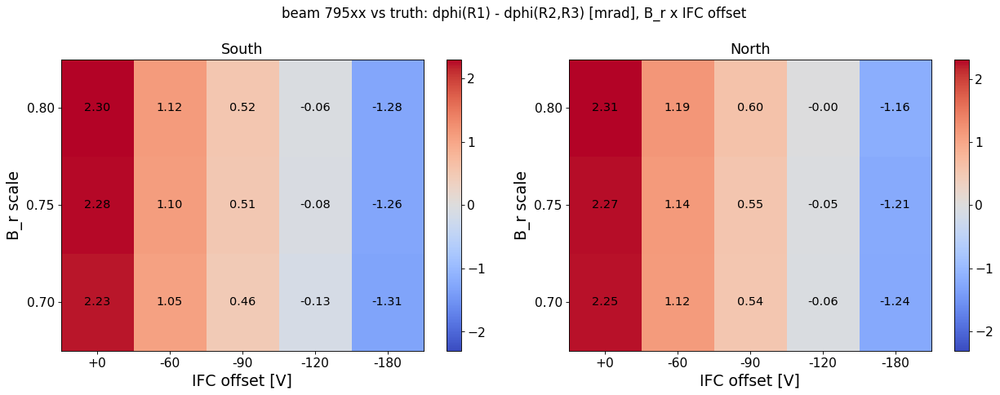

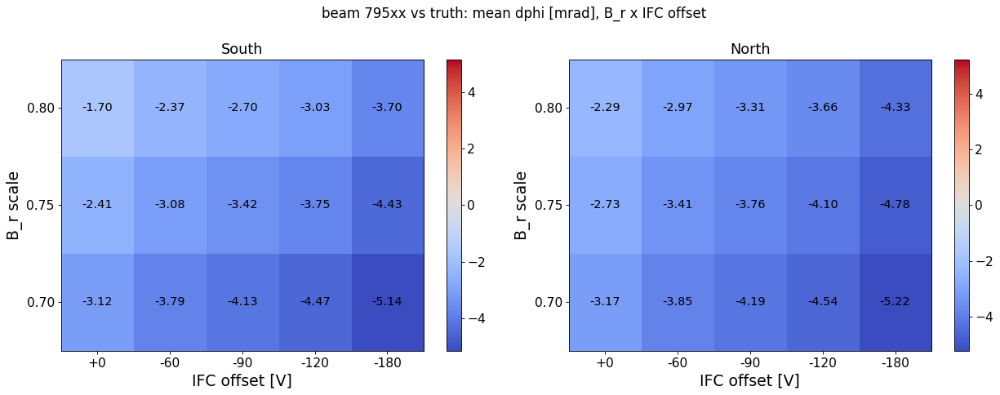

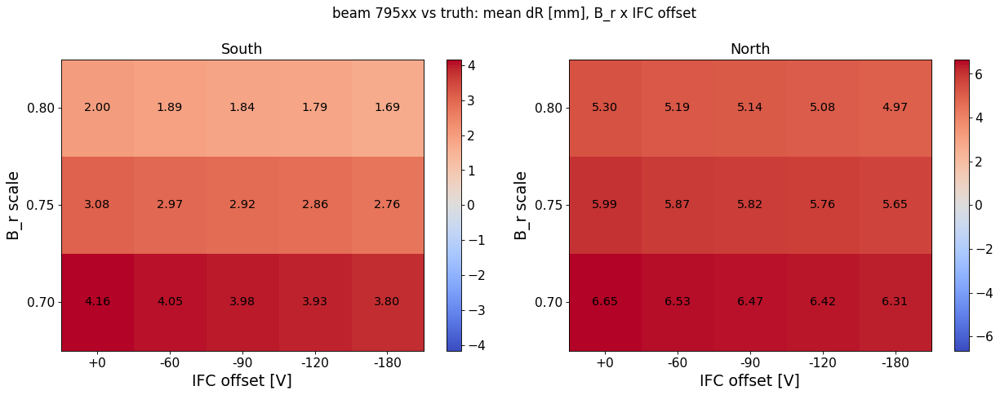

In [11]:
for lab, ref, runs, pre in sq.BS_CASES:
    print(f'CONFIG  {lab}: ' + STATIC + ' + B_r scale x IFC offset' + (' | alpha 1.6, keff = 0.60 x I_side' if pre == 'a1p6' else ''))
    show(sq.bsd_map(ref, runs, pre, 'rms', lab), sq.bsd_map(ref, runs, pre, 'shape', lab))
    show(sq.bsd_map(ref, runs, pre, 'mean', lab), sq.bsd_map(ref, runs, pre, 'dR', lab))

CONFIG  no beam 75073 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.75, IFC offset varied


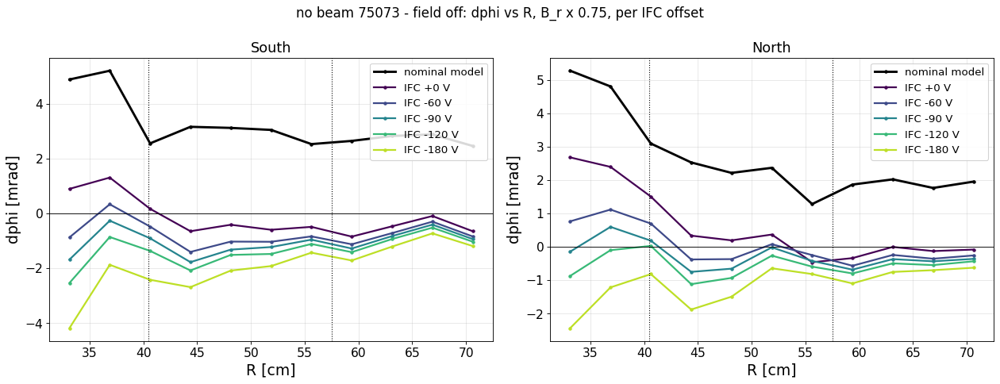

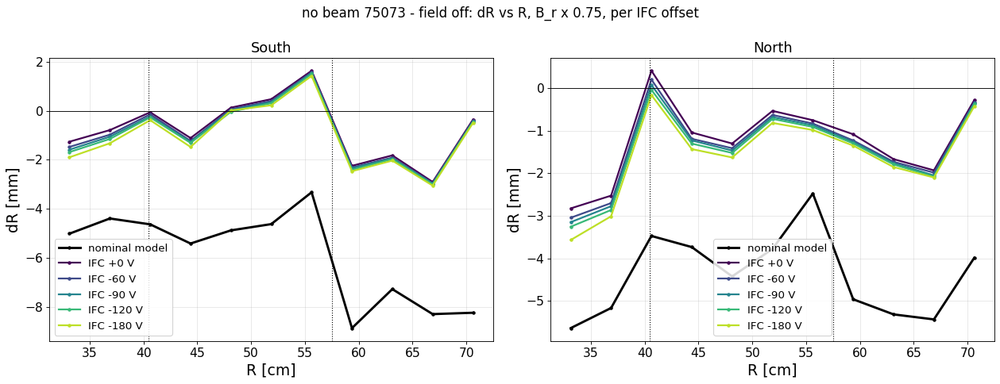

CONFIG  no beam 75073 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.80, IFC offset varied


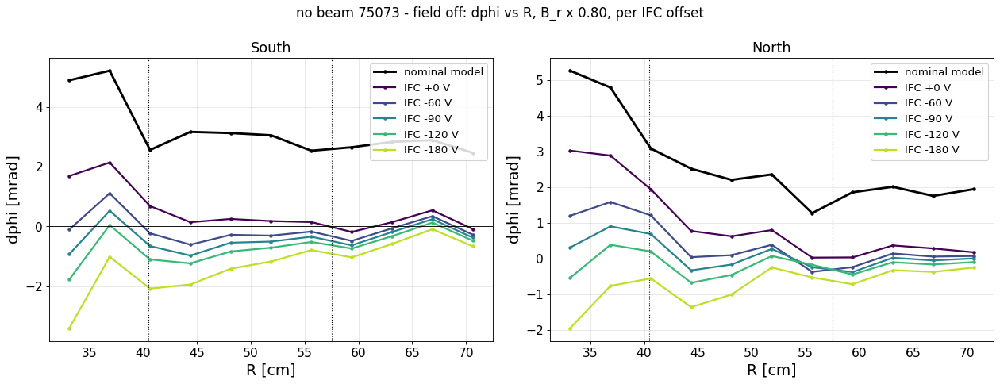

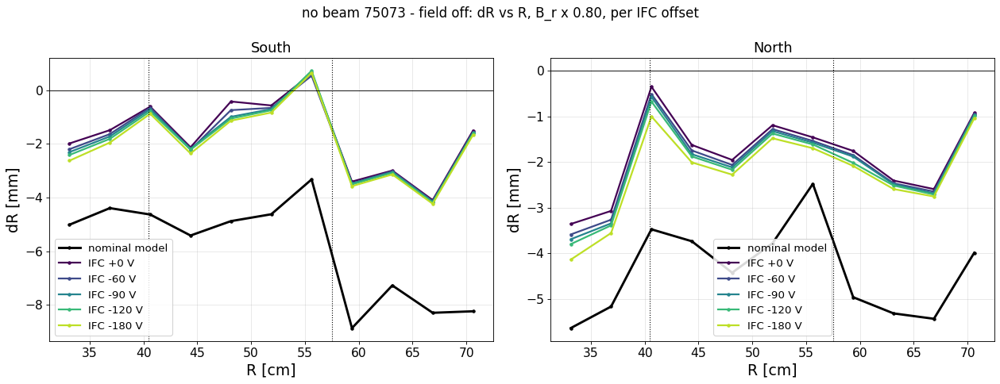

CONFIG  no beam 83319 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.75, IFC offset varied


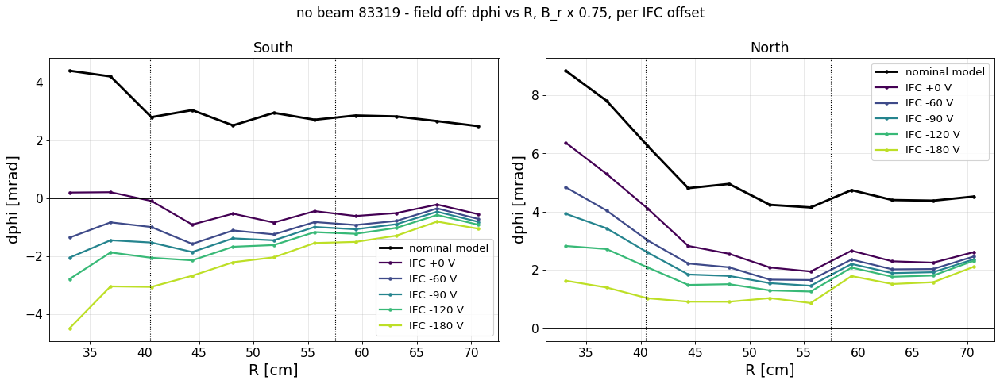

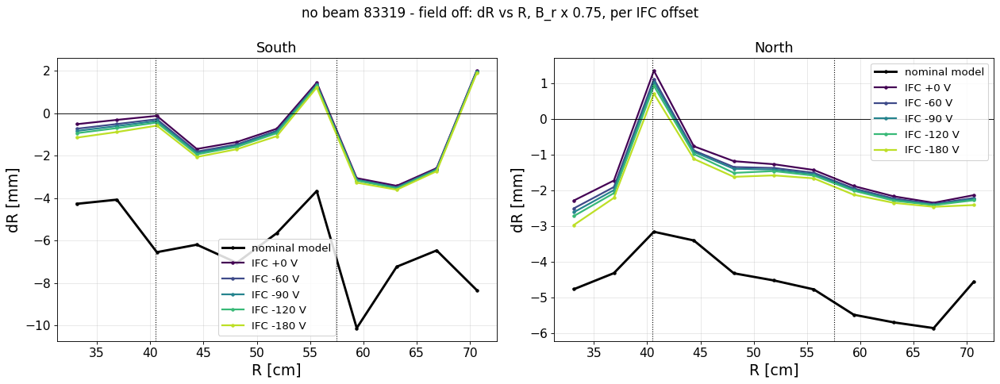

CONFIG  no beam 83319 - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.80, IFC offset varied


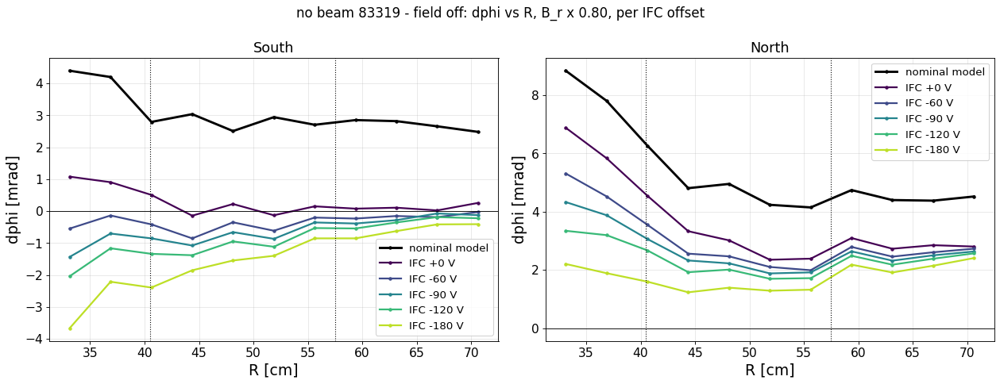

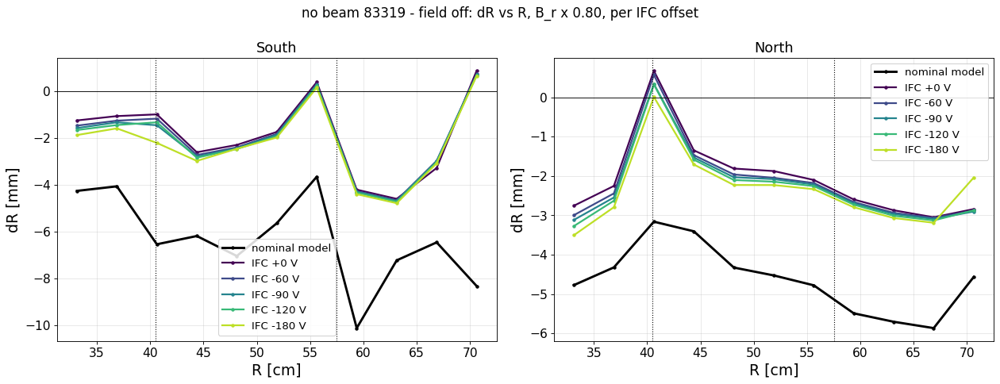

CONFIG  beam 795xx - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.75, IFC offset varied | alpha 1.6, keff = 0.60 x I_side


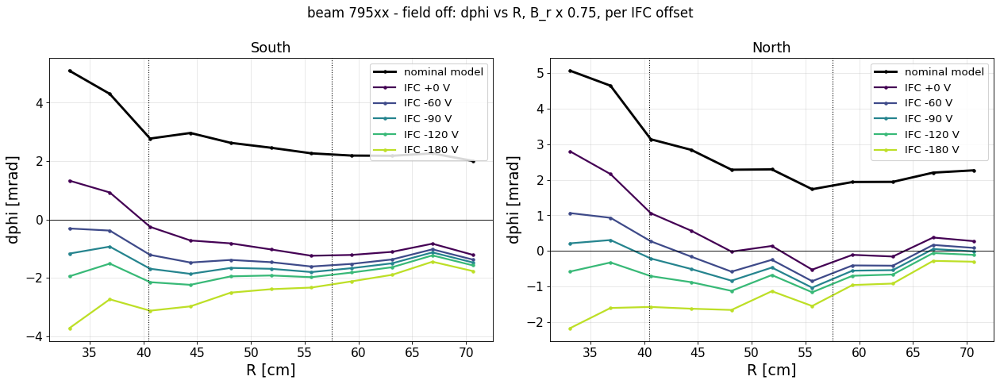

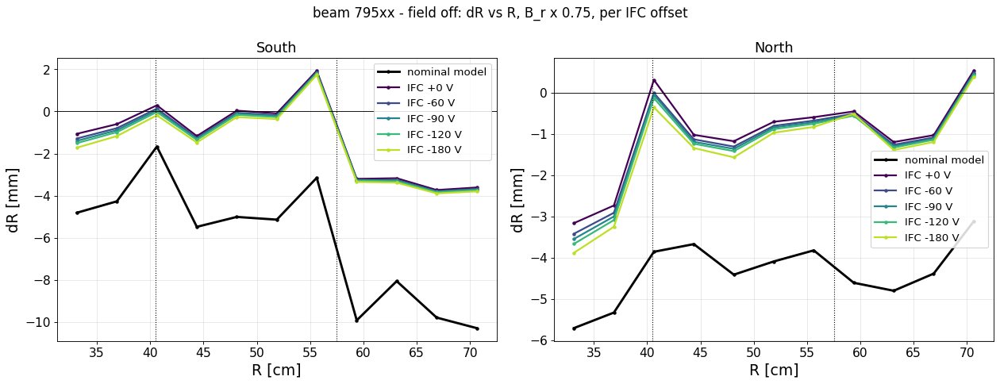

CONFIG  beam 795xx - field off: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.80, IFC offset varied | alpha 1.6, keff = 0.60 x I_side


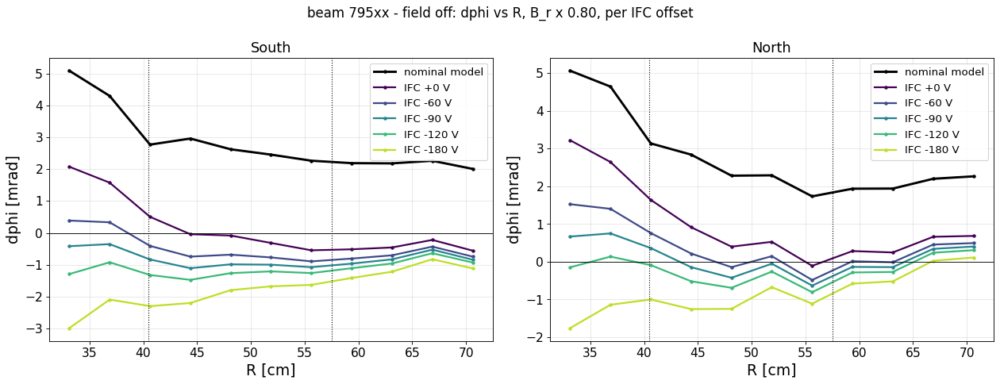

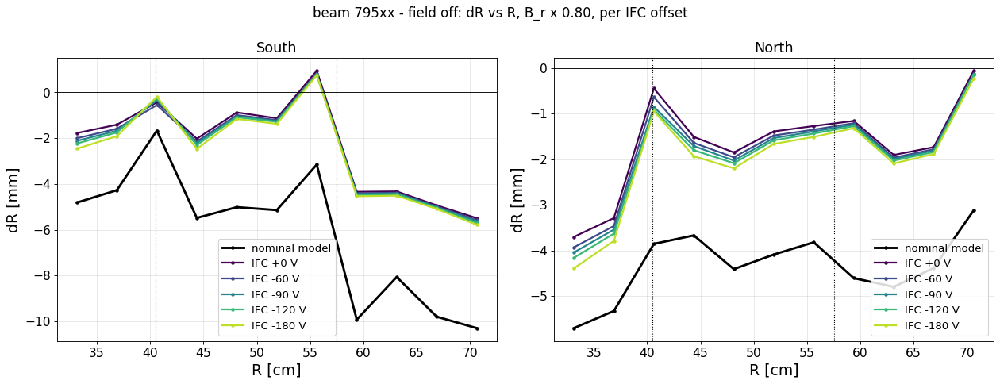

CONFIG  beam 795xx vs truth: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.75, IFC offset varied | alpha 1.6, keff = 0.60 x I_side


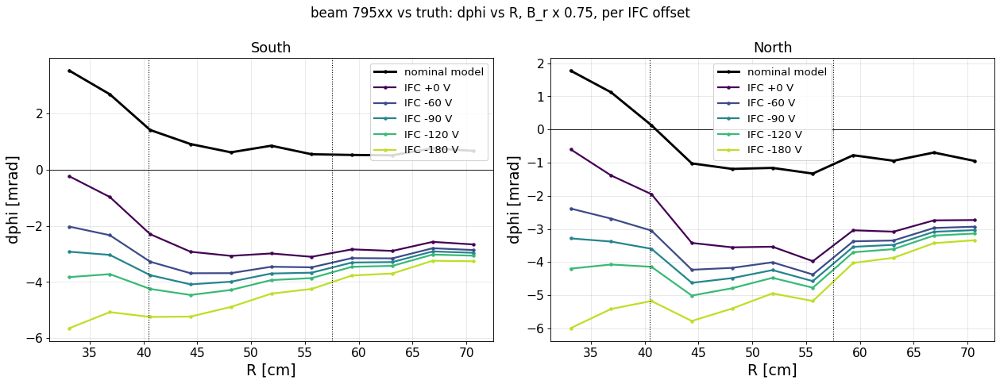

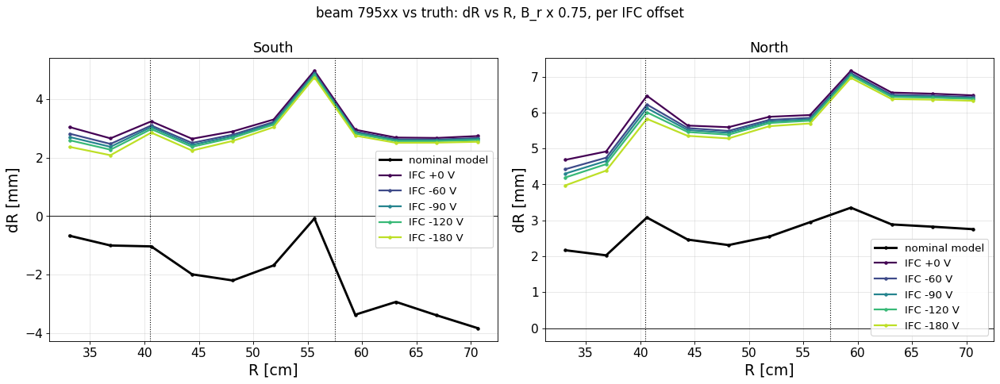

CONFIG  beam 795xx vs truth: static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x 0.80, IFC offset varied | alpha 1.6, keff = 0.60 x I_side


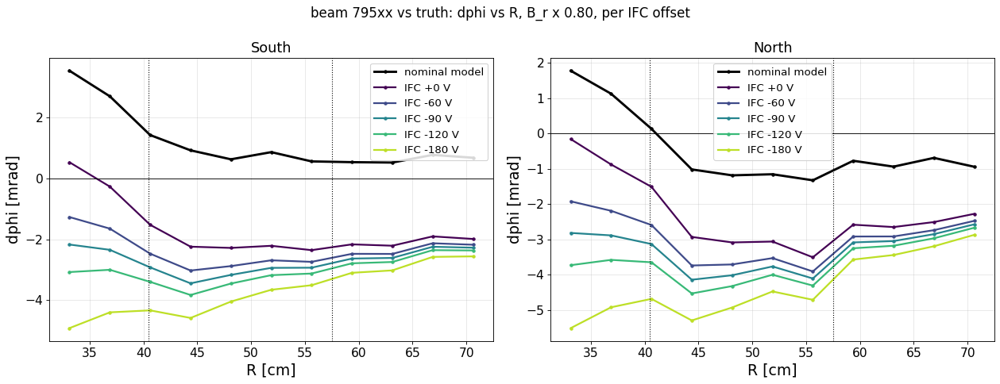

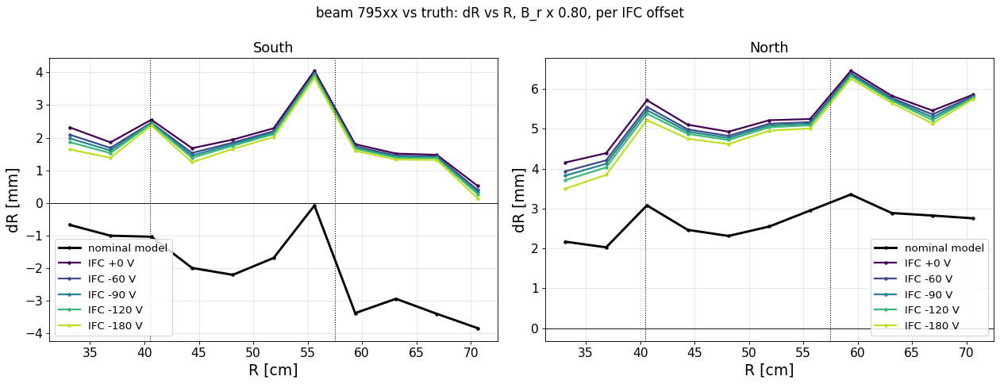

In [17]:
for lab, ref, runs, pre in sq.BS_CASES:
    for br in (75, 80):
        print(f'CONFIG  {lab}: ' + STATIC + f' + B_r x {br / 100:.2f}, IFC offset varied' + (' | alpha 1.6, keff = 0.60 x I_side' if pre == 'a1p6' else ''))
        show(sq.bsd_fig(ref, runs, pre, 'dphi', br, lab), sq.bsd_fig(ref, runs, pre, 'dR', br, lab))

### Result
- **The shape is cured by the IFC.** dφ(R1) − dφ(R2,R3) crosses 0 at about:
  - 75073: −90 V South, −130 V North;
  - beam 795xx: −120 V South, −130 V North;
  - 83319: −60 V South, ~−190 V North.

  It is independent of B_r, and the same in beam − field off and in beam vs truth.
- **Lowering the IFC also lowers the mean dφ** (−0.6 mrad per 60 V). So with the IFC fixed, the B_r that zeroes the mean
  moves up to ~0.8–0.9.
- **Best rms of the ring dφ** (2.9–3.3 mrad nominal):
  - 75073: 0.46 S (B_r 0.80, −60 V), 0.36 N (0.80, −120 V);
  - beam − field off: 0.66 S (0.80, −60 V), 0.41 N (0.80, −120 V).

  For South the optimum sits at the grid edge B_r 0.80.
- **Tension with dR.** dR wants B_r ≈ 0.70, while the dφ mean (with the IFC fix) wants ≈ 0.85. At the dφ optimum −2 to
  −2.5 mm of dR remain, and the IFC doesn't move dR. Something else drives dR (drift-velocity / E_z scale, the CM
  stripe radii, the field cage outer side).
- **83319 North is the outlier:** +2.6 mrad above 75073 North at every setting, and it needs ≳ −190 V.
- **Beam vs truth is worse with less static correction** (mean dφ goes negative): at b 0.60 the truth comparison wants
  more correction, so the space-charge keff vs truth will move. This needs the absolute keff redone with the new static
  model.

## 7. B_r × field cage with a consistent field-off reference (scan bsE)
The same field-cage model is now applied to field on **and** field off. 78242 is run with every field-cage setting, and
each field-on map is compared with the field-off map of the same setting (paired reference).

Grid:
- B_r × {0.8, 0.9};
- common IFC shift C ∈ {0, −60, −120} V;
- South − North difference D ∈ {−60, 0, +60} V around the automatic IFC (+211 / 0 after the change, 0 / 0 for 75073);
- OFC ∈ {−60, 0, +60} V;
- plus South frame 0 V.

Each side only feels its own IFC (South = auto + C + D/2, North = auto + C − D/2). D therefore tests the balance:
the best South and North shifts give the South − North difference the data want.

CONFIG  field off 78242 vs truth, B = 0, static model with IFC shift (OFC 0); South also frame 0


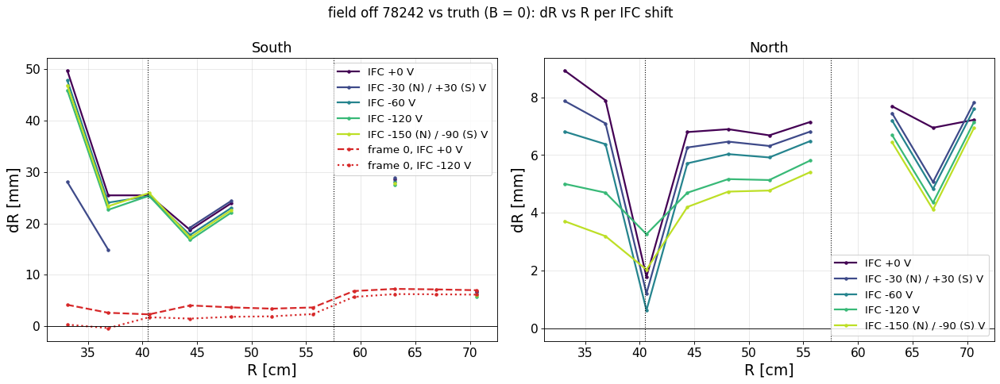

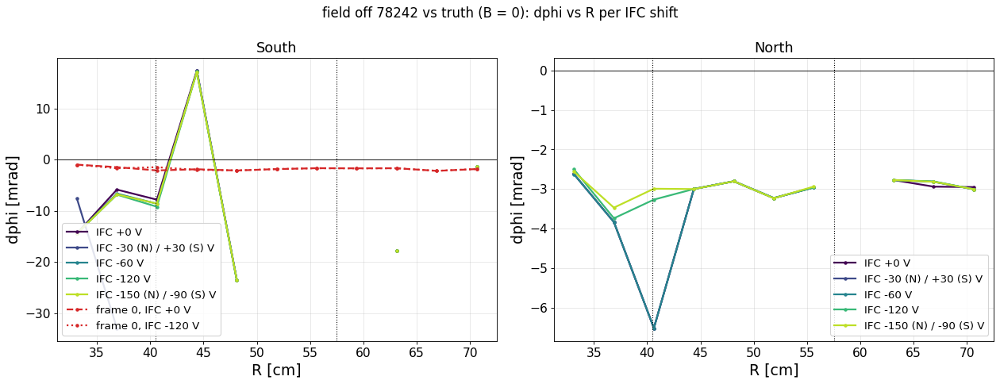

In [13]:
print('CONFIG  field off 78242 vs truth, B = 0, static model with IFC shift (OFC 0); South also frame 0')
show(sq.bse_offtruth_fig('dR'), sq.bse_offtruth_fig('dphi'))

CONFIG  no beam 75073 - field off (paired field-off reference): static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x IFC shift, OFC 0


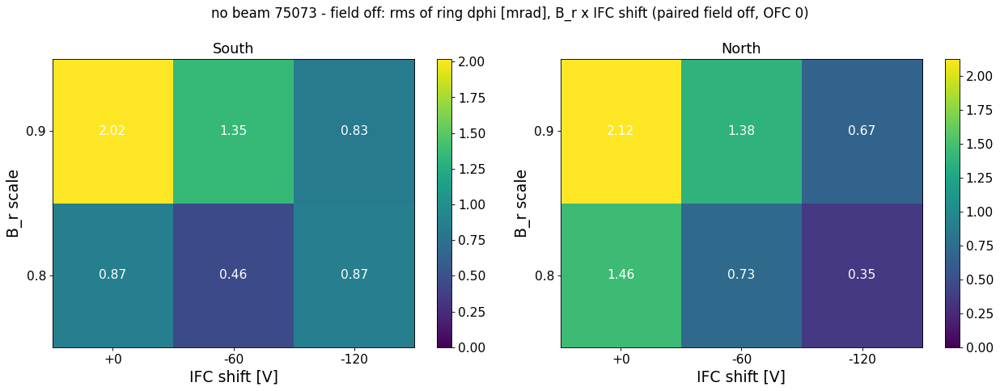

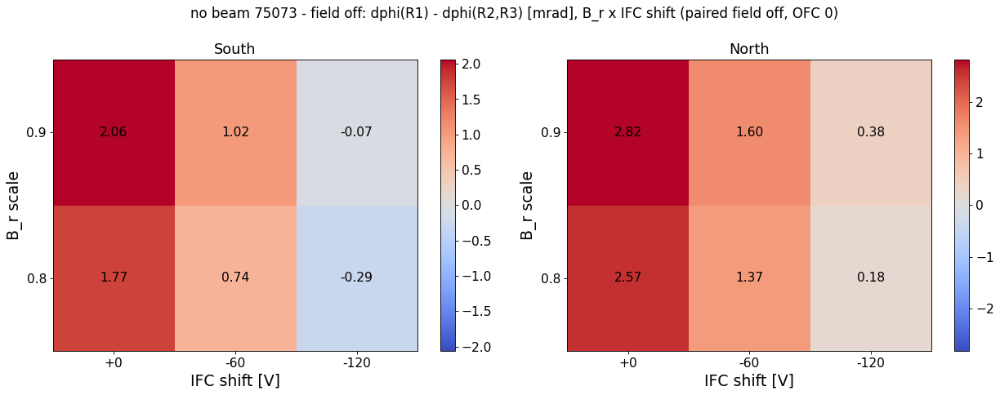

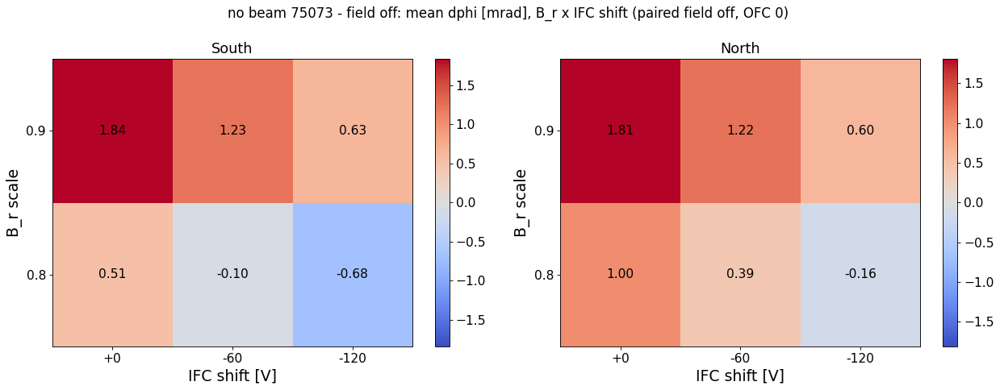

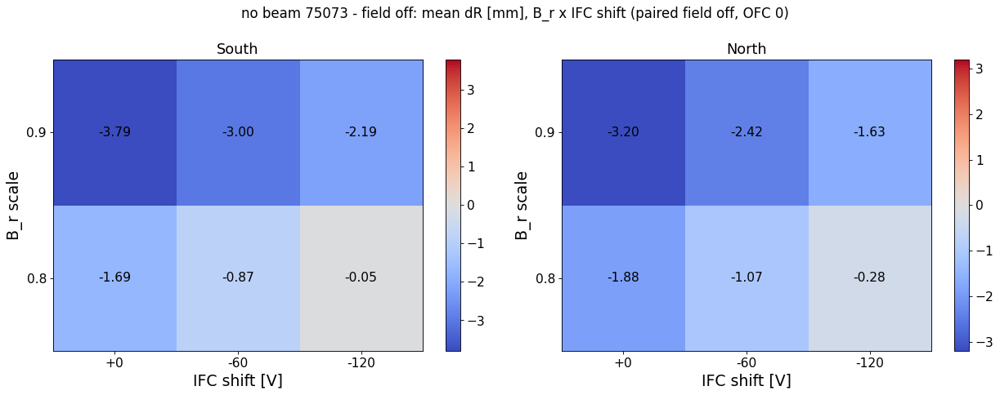

CONFIG  no beam 83319 - field off (paired field-off reference): static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x IFC shift, OFC 0


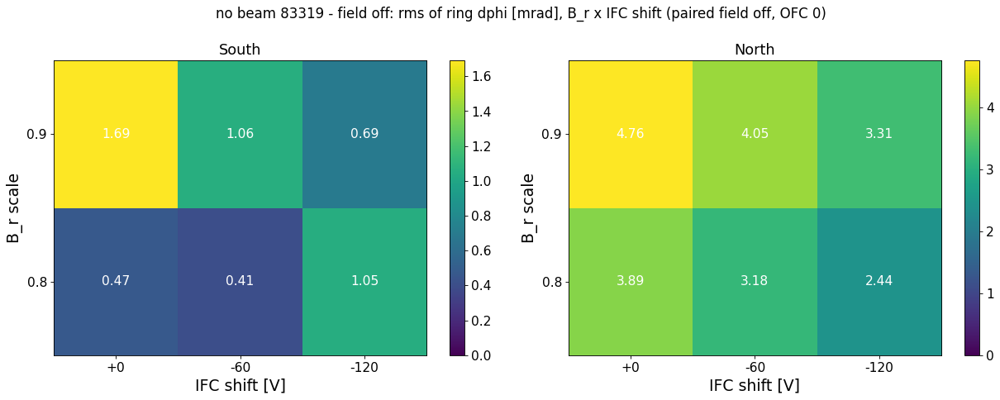

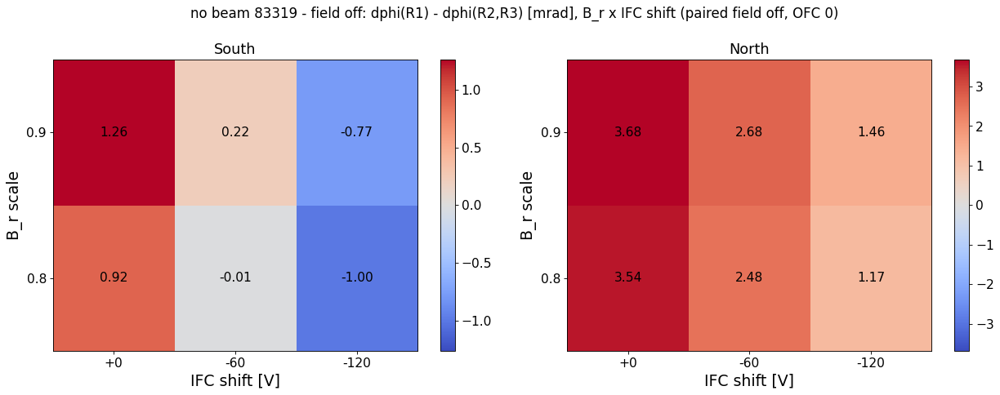

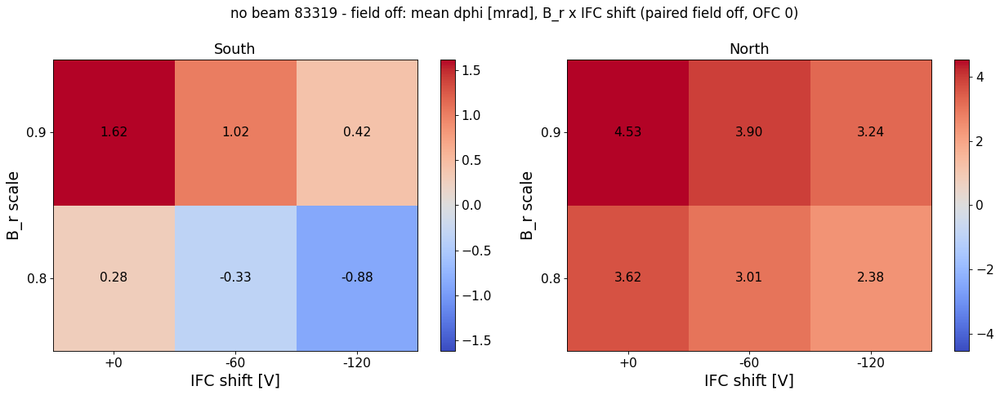

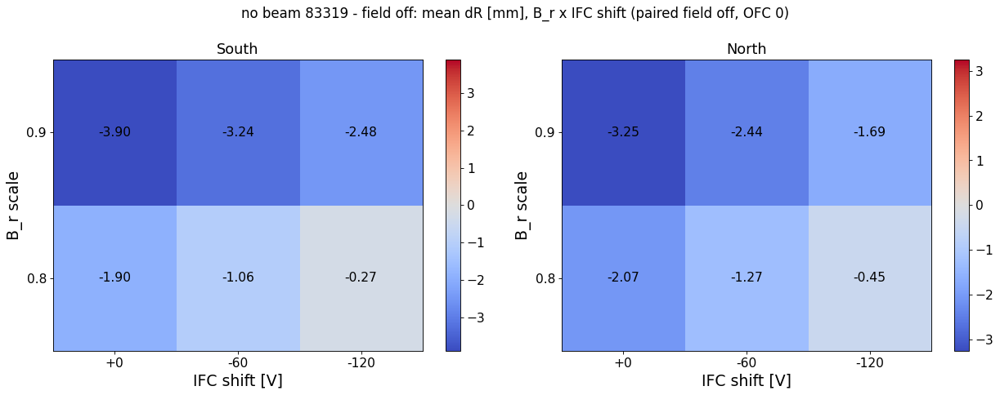

CONFIG  beam 795xx - field off (paired field-off reference): static correction (z -40 mm, tilt rot_x 0.16 / rot_y 0.85 mrad, survey x/y, P/T CM field, IFC automatic, frame -180) + B_r x IFC shift, OFC 0 | alpha 1.6, keff = 0.60 x I_side


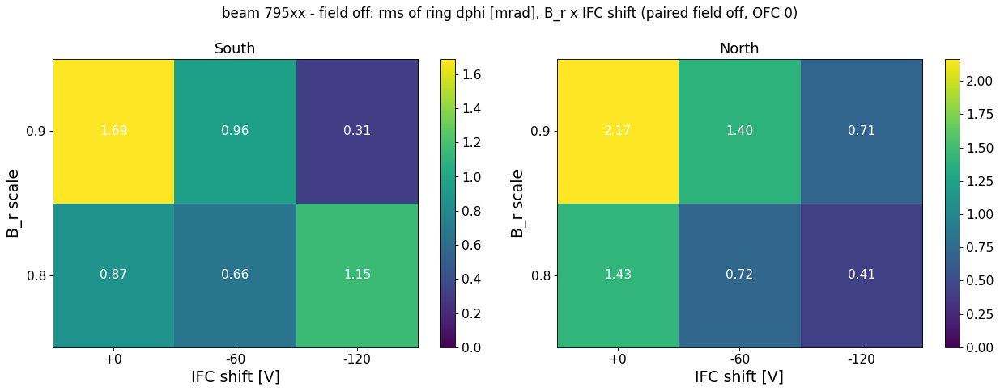

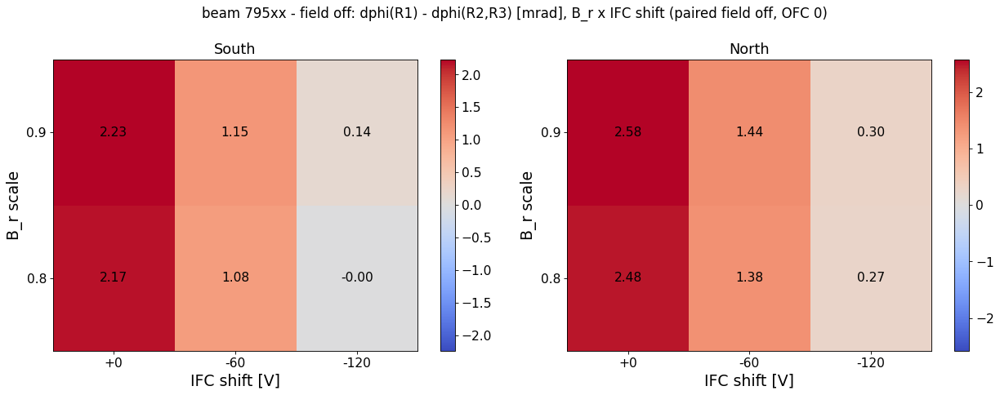

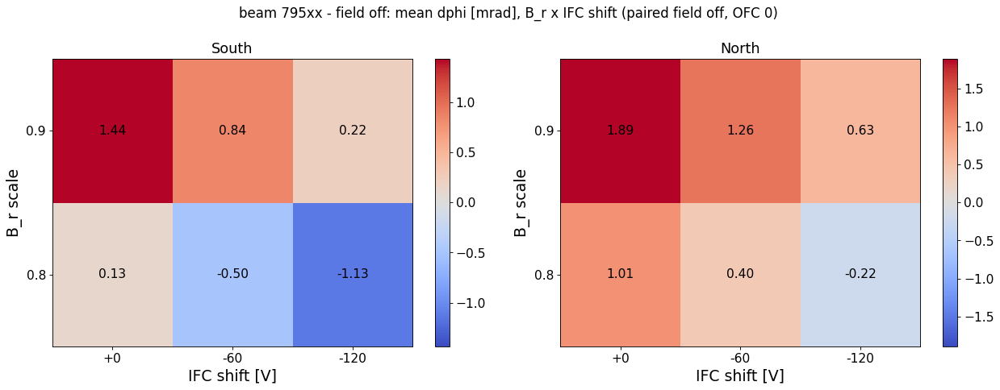

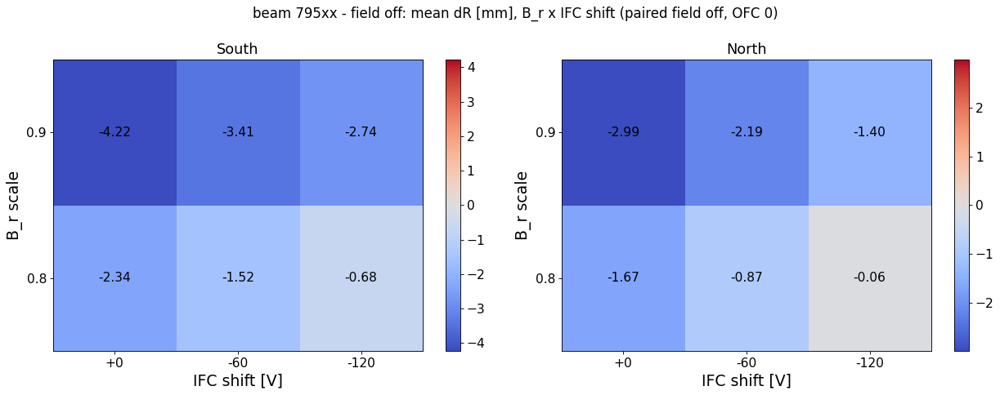

In [14]:
for lab, runs, pre in sq.BSE_CASES:
    print(f'CONFIG  {lab} (paired field-off reference): ' + STATIC + ' + B_r x IFC shift, OFC 0' + (' | alpha 1.6, keff = 0.60 x I_side' if pre == 'a1p6' else ''))
    show(sq.bse_map(lab, runs, pre, 'rms'), sq.bse_map(lab, runs, pre, 'shape'))
    show(sq.bse_map(lab, runs, pre, 'mean'), sq.bse_map(lab, runs, pre, 'dR'))

CONFIG  no beam 75073 - field off: nominal -> B_r 0.8 -> + IFC South -60 / North -120 V (relative to automatic) -> + South frame 0; paired field off


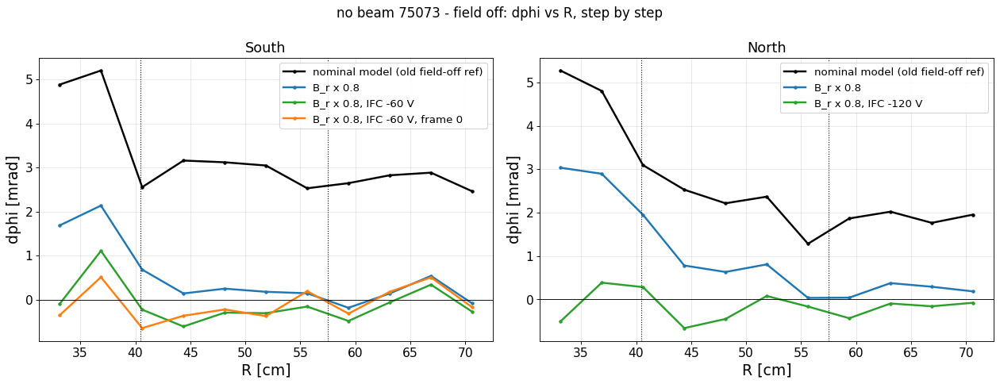

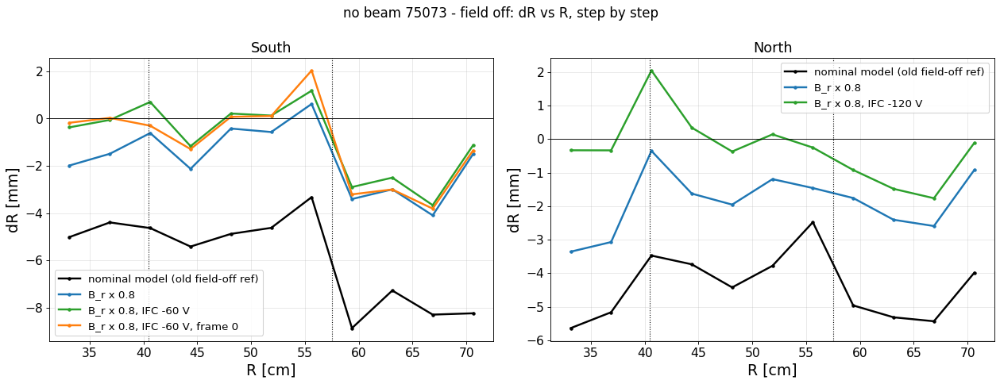

CONFIG  no beam 83319 - field off: nominal -> B_r 0.8 -> + IFC South -60 / North -120 V (relative to automatic) -> + South frame 0; paired field off


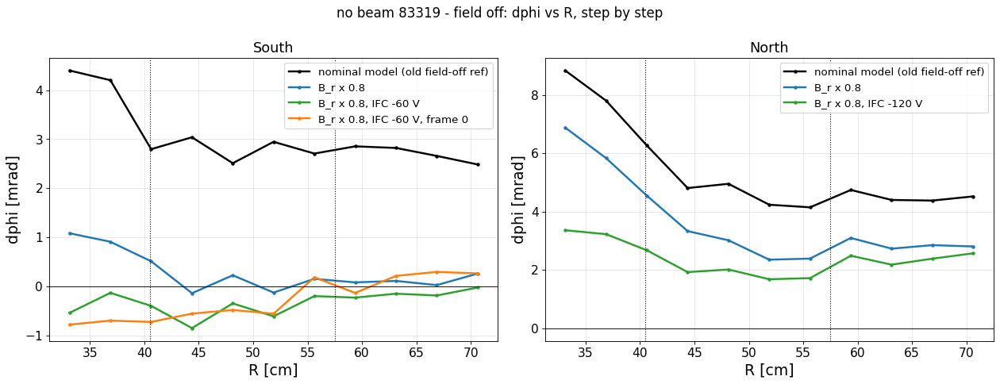

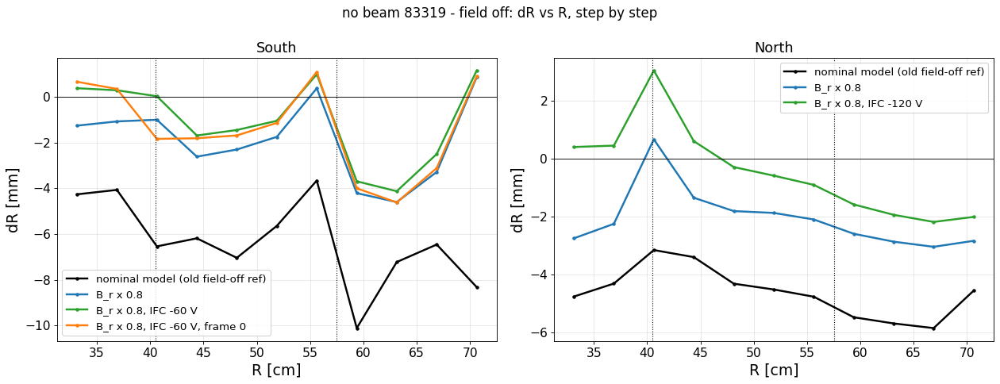

CONFIG  beam 795xx - field off: nominal -> B_r 0.8 -> + IFC South -60 / North -120 V (relative to automatic) -> + South frame 0; paired field off


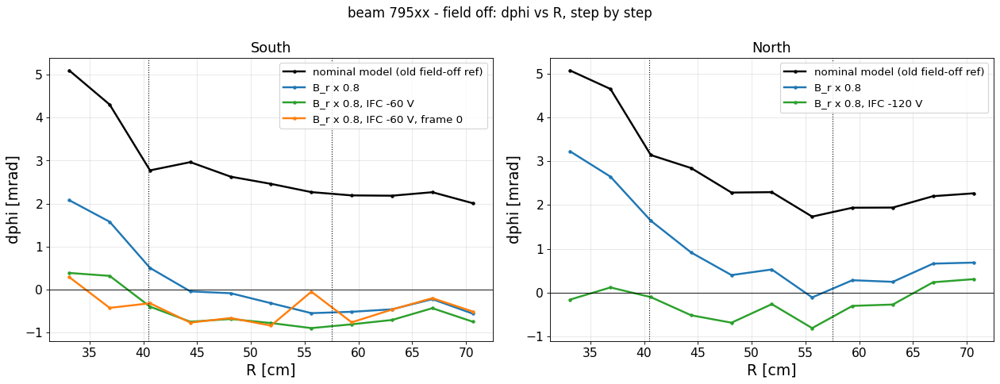

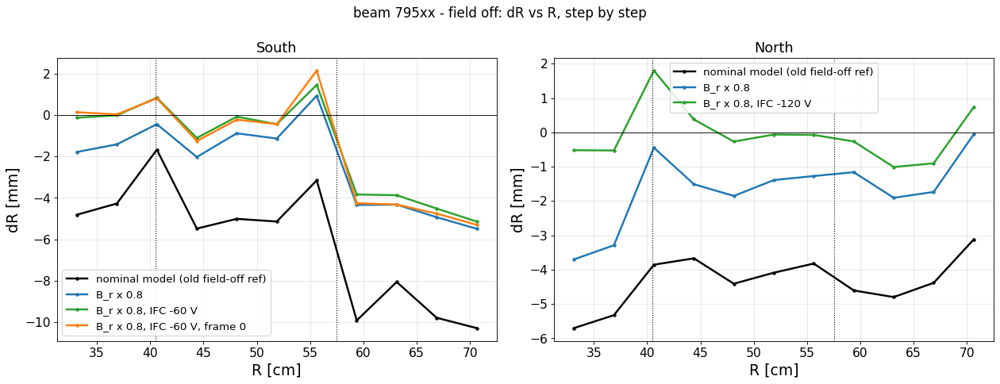

In [15]:
for lab, runs, pre in sq.BSE_CASES:
    print(f'CONFIG  {lab}: nominal -> B_r 0.8 -> + IFC South -60 / North -120 V (relative to automatic) -> + South frame 0; paired field off')
    show(sq.bse_best_fig(lab, runs, pre, 'dphi'), sq.bse_best_fig(lab, runs, pre, 'dR'))

### Result
- **The South − North balance stays.** The best IFC shift per side, relative to the automatic IFC, at B_r 0.8 and OFC 0:

  | | South | North |
  |---|---|---|
  | 75073 | −60 V | −120 V |
  | 795xx | −60 to −90 V | −120 V |
  | 83319 | −30 to −60 V | outlier |

  That is a South − North difference of 211 + 30…60 V: the automatic +211 V South step is confirmed, or even slightly
  larger. No step back toward the old imbalance.
- **Best ring-dφ rms** (nominal ≈ 3 mrad):
  - 75073: 0.38 South (with frame 0), 0.35 North;
  - 795xx beam: 0.54 South (frame 0), 0.41 North;
  - 83319 South: 0.23.
- **dR: the paired reference closes most of the gap at B_r 0.8.**
  - North mean dR goes to −0.1 to −0.3 mm (it was −2 mm with the old reference).
  - South is −1 to −1.5 mm, with an R1 − R2,3 dR shape of +2 to +3 mm that no knob removes.
  - B_r 0.9 is worse in dR everywhere, so B_r 0.8 it is.
- **OFC ±60 V is a weak knob** (≈ ∓1 mm in dR, little in dφ). It doesn't fix the South dR shape.
- **South frame 0:**
  - field off vs truth matches properly only with South frame 0. With −180, half the clusters are lost and dR is 20–25
    mm, i.e. wrong-stripe matching;
  - in field on − field off it lowers the R1 dφ by ~0.6 mrad (similar to −30 V of IFC) and improves the rms a little.
- **Field off vs truth (no B) pins the IFC independently.**
  - North: the R1 dR excess goes to zero at about −85 V, consistent with the −120 V from dφ with B on.
  - South (frame 0 only, since −180 mis-matches): R1 lines up with R2 at about −120 V, also consistent. A +4 mm dR step
    at the R2/R3 boundary (57.5 cm) dominates the R1 − R2,3 number there and is not an IFC effect.
  - Both sides show a constant dR offset of +4 to +7 mm vs truth that no field-cage setting explains: CM stripe radii in
    the truth table or the drift / z model.
- **83319 North is still off by +2 to +3 mrad at every setting.**

## Notes for the next step
- **Tilt:** use the per-geometry sine amplitudes (section 3) to fit rot_x and rot_y per side. The survey values are rot_x
  0.298, rot_y 1.485 mrad, against the 0.16 / 0.85 used here. A remaining sine that doesn't follow the rotation points
  to an x/y shift or a field-cage asymmetry.
- **z:** the z dependence of no beam − field off is weak (section 4). z is pinned by the beam.
- **B_r (section 5):** B_r × ~0.75 removes the constant dφ and dR on both sides. The remaining sagitta (~−200 µm
  South, ~−370 µm North) and the R1 step need another knob: the IFC offset (−3.1 µm/V) or the frames. Next scan: B_r
  {0.65, 0.7, 0.75, 0.8} × IFC offsets × the tilt toward the survey / beam axis. Check with the track keff scan at
  B_r 0.75 (does keff come down toward the space-charge b ≈ 0.6?).